# IND320 – Project Work Part 4: Machine Learning

**Name:** Alina Shah

**GitHub repository:** https://github.com/59762/IND320-59762 

**Streamlit app:** https://ind320-59762.streamlit.app/

## 1. Setup

In [28]:
%pip install river
%pip install geopandas shapely
%pip install plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------  9.7/9.7 MB 50.2 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 43.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
#  Imports 
import io
import json
import os
import re
import time
import tomllib
import warnings
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from datetime import date, datetime, timedelta
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

# River = online (streaming) machine learning. Models learn one observation at a time.
from river import forest, linear_model, optim, preprocessing, time_series

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
np.random.seed(42)                                   # reproducible sampling and random forests

#  Paths
# ROOT = project root, whether the notebook is started from the root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE_DIR = ROOT / "data" / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

#  API endpoints and constants 
OSLO = "Europe/Oslo"                                 # the one local timezone used in this project
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
OPENMETEO_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
NB_EXR_URL = "https://data.norges-bank.no/api/data/EXR"
ENTSOE_API = "https://web-api.tp.entsoe.eu/api"

print("Project root:", ROOT)
print("Cache folder:", CACHE_DIR)

Project root: c:\Users\Alina\OneDrive - Norwegian University of Life Sciences\NMBU\IND320 - Høst 2026\IND320-59762
Cache folder: c:\Users\Alina\OneDrive - Norwegian University of Life Sciences\NMBU\IND320 - Høst 2026\IND320-59762\data\cache


In [3]:
#  Secrets (never print the values) 
def load_secrets(path=None) -> dict:
    # Read .streamlit/secrets.toml if it exists; return {} otherwise
    p = Path(path) if path else ROOT / ".streamlit" / "secrets.toml"
    if p.exists():
        with open(p, "rb") as f:
            return tomllib.load(f)
    return {}


SECRETS = load_secrets()
ENTSOE_TOKEN = SECRETS.get("entsoe_token") or os.getenv("ENTSOE_TOKEN")
print("ENTSO-E token found:", bool(ENTSOE_TOKEN))


#  One HTTP helper for all APIs 
def _redact(text: str) -> str:
    # Remove the ENTSO-E token from error messages (they contain the full URL)
    return re.sub(r"securityToken=[^&\s'\"]+", "securityToken=***", str(text))


def http_get(url, params=None, timeout=60, retries=3, backoff=2.0):
    # GET with retries for temporary errors (timeouts, HTTP 429 and 5xx).
    # Permanent errors (400, 401, 404 ...) fail immediately with a readable message.
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
        except (requests.ConnectionError, requests.Timeout) as exc:
            last_error = exc
        else:
            if r.status_code == 429 or r.status_code >= 500:
                last_error = f"HTTP {r.status_code}"
            else:
                try:
                    r.raise_for_status()
                except requests.HTTPError as exc:
                    raise RuntimeError(f"HTTP {r.status_code} from {url}: {_redact(exc)}") from None
                return r
        if attempt < retries:
            time.sleep(backoff * attempt)                  # wait a little longer each time
    raise RuntimeError(f"No answer from {url} after {retries} attempts: {_redact(last_error)}")

ENTSO-E token found: True


## 2. Norges Bank exchange rates (EUR and USD)

Norges Bank publishes official exchange rates through an open API:
`https://data.norges-bank.no/api/data/EXR/<key>?format=...&startPeriod=...&endPeriod=...`

The key `B.EUR.NOK.SP` is read as *B* = business-daily frequency, *EUR* = base currency, *NOK* = quote currency,
*SP* = spot. The value is therefore **NOK per 1 EUR** (or per 1 USD).

In [4]:
def parse_norges_bank_csv(text: str) -> pd.DataFrame:
    # Parse one CSV answer from Norges Bank to a DataFrame indexed by date, one column per currency.
    # Example columns: EURNOK (NOK per 1 EUR).
    first_line = text.lstrip().splitlines()[0]
    sep = ";" if first_line.count(";") > first_line.count(",") else ","
    raw = pd.read_csv(io.StringIO(text), sep=sep)

    # Find the needed columns by name (case-insensitive)
    cols = {c.strip().upper(): c for c in raw.columns}
    time_col = cols.get("TIME_PERIOD") or cols.get("TIME")
    value_col = cols.get("OBS_VALUE")
    cur_col = cols.get("BASE_CUR")
    if not (time_col and value_col and cur_col):
        raise ValueError(f"Unexpected columns from Norges Bank: {list(raw.columns)}")

    out = pd.DataFrame({
        "date": pd.to_datetime(raw[time_col]),
        "cur": raw[cur_col].astype(str).str.upper().str.strip(),
        # decimal comma safety: "11,52" -> 11.52
        "rate": pd.to_numeric(raw[value_col].astype(str).str.replace(",", ".", regex=False),
                              errors="coerce"),
    })
    wide = out.pivot_table(index="date", columns="cur", values="rate", aggfunc="last").sort_index()
    wide.columns = [f"{c}NOK" for c in wide.columns]
    wide.columns.name = None
    return wide


def download_exchange_rates(currencies=("EUR", "USD"), start="2015-01-01", end=None,
                            use_cache=True, max_age_hours=12, timeout=30) -> pd.DataFrame:
    # Download daily (business-day) NOK exchange rates from the Norges Bank API.
    #   currencies : ISO codes, default EUR and USD
    #   start, end : 'YYYY-MM-DD' (end=None means today)
    #   use_cache  : reuse a CSV in data/cache that is younger than max_age_hours
    # Returns a DataFrame indexed by date with columns EURNOK, USDNOK (NOK per 1 unit).
    end = end or date.today().isoformat()
    frames = []
    for cur in currencies:
        cache = CACHE_DIR / f"fx_{cur}_{start}_{end}.csv"
        fresh = cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600
        if use_cache and fresh:
            frames.append(pd.read_csv(cache, index_col=0, parse_dates=True))
            continue

        url = f"{NB_EXR_URL}/B.{cur}.NOK.SP"
        parsed, errors = None, []
        for fmt in ("csv", "sdmx-csv"):                   # documented format first, SDMX as fallback
            params = {"format": fmt, "startPeriod": start, "endPeriod": end, "locale": "en"}
            try:
                parsed = parse_norges_bank_csv(http_get(url, params=params, timeout=timeout).text)
                break
            except Exception as exc:                      # try the next format
                errors.append(f"{fmt}: {exc}")
        if parsed is None or parsed.empty:
            raise RuntimeError(f"Could not download {cur} from Norges Bank. " + " | ".join(errors))
        parsed.to_csv(cache)
        frames.append(parsed)
        time.sleep(0.2)                                   # be polite to the API

    return pd.concat(frames, axis=1).sort_index()

Shape: (2997, 2) | period: 2015-01-02 -> 2026-11-26


,EURNOK,USDNOK
date,,
2015-01-02,9.0420,7.5081
2015-01-05,9.1075,7.6437
2015-01-06,9.1795,7.7048
2015-01-07,9.1500,7.7339
2015-01-08,9.0280,7.6717


,EURNOK,USDNOK
date,,
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076
2026-11-24,10.7350,9.7920
2026-11-25,10.7778,9.8562
2026-11-26,10.7180,9.7658



All sanity checks passed.

Observations per weekday (expect Monday-Friday only):
date
Monday       587
Tuesday      612
Wednesday    611
Thursday     589
Friday       598
Saturday       0
Sunday         0


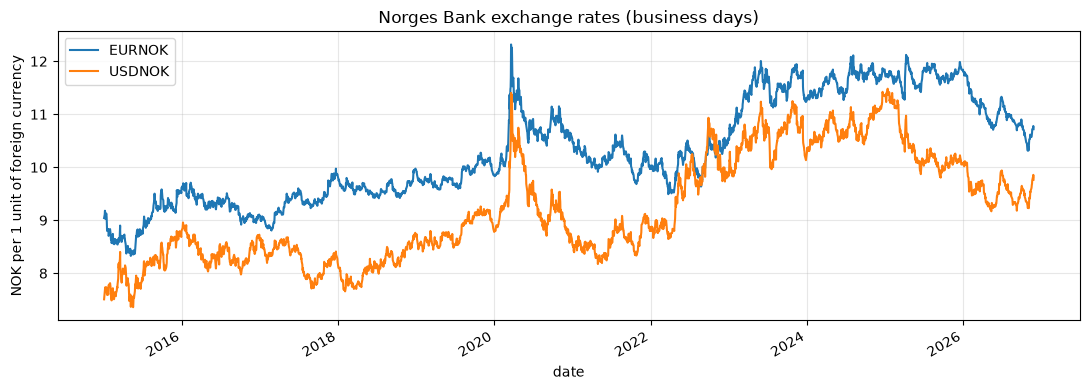

In [5]:
# Test the download function 
fx = download_exchange_rates(("EUR", "USD"), start="2015-01-01")

print("Shape:", fx.shape, "| period:", fx.index.min().date(), "->", fx.index.max().date())
display(fx.head())
display(fx.tail())

# Sanity checks: fail loudly instead of silently continuing with a bad series
assert {"EURNOK", "USDNOK"} <= set(fx.columns), "a currency column is missing"
assert fx.notna().mean().min() > 0.95, "too many missing values"
assert fx.apply(lambda s: s.between(5, 20)).all().all(), "implausible exchange rates"
print("\nAll sanity checks passed.")

print("\nObservations per weekday (expect Monday-Friday only):")
print(fx.index.day_name().value_counts()
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
      .fillna(0).astype(int).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
fx.plot(ax=ax)
ax.set_ylabel("NOK per 1 unit of foreign currency")
ax.set_title("Norges Bank exchange rates (business days)")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 3. Timezone investigation

Norway uses CET (UTC+1) in winter and CEST (UTC+2) in summer. In 2024 the clocks moved on **Sun 31 March** (a 23-hour day) and **Sun 27 October** (a 25-hour day). These two days are used as test cases below.

### 3.1 Magasinstatistikk (NVE)

What to check: does `dato_Id` contain a clock time or an offset, which weekday do the observations fall on, and is the spacing regular? The weekday decides how all other sources must be grouped into weeks.

In [6]:
NVE_RENAME = {
    "dato_Id": "date", "omrType": "area_type", "omrnr": "area_nr", "iso_aar": "year",
    "iso_uke": "week", "fyllingsgrad": "fill_percentage", "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "fill_TWh", "neste_Publiseringsdato": "next_publish_date",
    "fyllingsgrad_forrige_uke": "prev_week_fill_pct", "endring_fyllingsgrad": "change_fill_pct",
}
WEEKDAY_CODE = ["MON", "TUE", "WED", "THU", "FRI", "SAT", "SUN"]     # pandas 'W-<code>' anchors


def load_nve_raw(refresh=False, max_age_hours=24) -> pd.DataFrame:
    # Raw Magasinstatistikk data for all areas, cached as CSV for max_age_hours
    cache = CACHE_DIR / "nve_raw.csv"
    fresh = cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600
    if fresh and not refresh:
        return pd.read_csv(cache)
    df = pd.DataFrame(http_get(f"{NVE_BASE}/HentOffentligData", timeout=60).json())
    df.to_csv(cache, index=False)
    return df


def load_nve_all(refresh=False) -> pd.DataFrame:
    # Cleaned data: English column names, real datetimes, sorted by date
    df = load_nve_raw(refresh).rename(columns=NVE_RENAME)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)


def detect_nve_anchor(nve: pd.DataFrame) -> str:
    # The weekday on which most observations fall, as a pandas anchor code ('SUN', 'MON', ...)
    return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


nve_raw = load_nve_raw()
nve = load_nve_all()
NVE_ANCHOR = detect_nve_anchor(nve)
no3 = nve[(nve["area_type"] == "EL") & (nve["area_nr"] == 3)]

print("Raw 'dato_Id' examples:         ", nve_raw["dato_Id"].head(3).tolist())
print("Rows:", len(nve), "| area types:", sorted(nve["area_type"].unique()))
print("Any clock time in 'date'?       ", bool(((nve["date"].dt.hour != 0) | (nve["date"].dt.minute != 0)).any()))
print("Observations per weekday:       ", nve["date"].dt.day_name().value_counts().to_dict())
print("Spacing between NO3 rows (days):", no3["date"].diff().dt.days.value_counts().to_dict())
print("=> NVE anchor weekday used in this project:", NVE_ANCHOR)
print("Fill column range (unit check, 0-1 or 0-100):",
      round(float(no3["fill_percentage"].min()), 3), "-", round(float(no3["fill_percentage"].max()), 3))

Raw 'dato_Id' examples:          ['2020-11-15', '2011-08-28', '1998-07-05']
Rows: 14976 | area types: ['EL', 'NO', 'VASS']
Any clock time in 'date'?        False
Observations per weekday:        {'Sunday': 14976}
Spacing between NO3 rows (days): {7.0: 1663}
=> NVE anchor weekday used in this project: SUN
Fill column range (unit check, 0-1 or 0-100): 0.107 - 0.986


C:\Users\Alina\AppData\Local\Temp\ipykernel_15188\3849431921.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


### 3.2 Open-Meteo

The parameter `timezone` decides how Open-Meteo writes its timestamps. The response has **no UTC offset in the timestamps**, so the timezone must be known from the request. The existing `download_weather()` from notebook 3 uses `timezone=Europe/Oslo`, which gives *naive local wall-clock times*. On DST days this is ambiguous: 02:00-03:00 does not exist on 2024-03-31 and happens twice on 2024-10-27.

The test requests the same three-day windows in UTC and in Europe/Oslo, converts the Oslo version to UTC and compares the two. If the conversion is correct, no hours should be missing and no values should differ.

In [7]:
def openmeteo_hourly(lat, lon, start, end, tz, variable="temperature_2m"):
    # One point, one hourly variable. Returns the series (naive index, as sent by the API)
    # and some metadata that the API sends back about the timezone.
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "hourly": variable, "models": "era5", "timezone": tz, "timeformat": "iso8601"}
    j = http_get(OPENMETEO_ARCHIVE, params=params, timeout=30).json()
    s = pd.Series(j["hourly"][variable], index=pd.to_datetime(j["hourly"]["time"]), name=variable)
    meta = {k: j.get(k) for k in ("timezone", "timezone_abbreviation", "utc_offset_seconds")}
    return s, meta


def oslo_naive_to_utc(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    # Convert naive Europe/Oslo wall-clock timestamps to timezone-aware UTC.
    #  - ambiguous='infer' resolves the repeated hour on the fall-back day, but only if the
    #    repeated hour really is present as duplicate rows.
    #  - otherwise the ambiguous hour becomes NaT (it is never silently shifted by one hour).
    #  - non-existent spring-forward times are shifted forward.
    try:
        local = index.tz_localize(OSLO, ambiguous="infer", nonexistent="shift_forward")
    except Exception:
        local = index.tz_localize(OSLO, ambiguous="NaT", nonexistent="shift_forward")
    return local.tz_convert("UTC")


LAT, LON = 63.4, 10.4          # Trondheim area (NO3). Only used for this timezone check.
DST_WINDOWS = {"spring forward (31 Mar 2024)": ("2024-03-30", "2024-04-01"),
               "fall back (27 Oct 2024)":      ("2024-10-26", "2024-10-28")}

rows = []
for label, (d0, d1) in DST_WINDOWS.items():
    s_utc, meta_utc = openmeteo_hourly(LAT, LON, d0, d1, "UTC")
    s_osl, meta_osl = openmeteo_hourly(LAT, LON, d0, d1, OSLO)

    # Oslo request -> UTC, then compare with the UTC request hour by hour
    osl_as_utc = pd.Series(s_osl.values, index=oslo_naive_to_utc(s_osl.index))
    osl_as_utc = osl_as_utc[osl_as_utc.index.notna()]
    osl_as_utc = osl_as_utc[~osl_as_utc.index.duplicated()]
    aligned = osl_as_utc.reindex(s_utc.index.tz_localize("UTC"))
    diff = (aligned.to_numpy() - s_utc.to_numpy())

    expected_oslo_hours = len(pd.date_range(f"{d0} 00:00", f"{d1} 23:00", freq="h", tz=OSLO))
    rows.append({
        "window": label,
        "rows (UTC request)": len(s_utc),
        "rows (Oslo request)": len(s_osl),
        "real hours in the Oslo window": expected_oslo_hours,
        "duplicate Oslo timestamps": int(s_osl.index.duplicated().sum()),
        "hours lost in conversion": int(np.isnan(diff).sum()),
        "values that differ": int((np.abs(diff[~np.isnan(diff)]) > 0.05).sum()),
        "API offset (Oslo req.)": meta_osl["utc_offset_seconds"],
    })

openmeteo_check = pd.DataFrame(rows).set_index("window").T
display(openmeteo_check)

bad = openmeteo_check.loc[["hours lost in conversion", "values that differ"]].to_numpy().sum()
print("Verdict:", "Oslo-time request converts cleanly to UTC." if bad == 0 else
      "Oslo-time request is NOT safe on DST days -> download hourly data with timezone=UTC.")

window,spring forward (31 Mar 2024),fall back (27 Oct 2024)
rows (UTC request),72,72
rows (Oslo request),72,72
real hours in the Oslo window,71,73
duplicate Oslo timestamps,0,0
hours lost in conversion,2,3
values that differ,42,21
API offset (Oslo req.),3600,3600


Verdict: Oslo-time request is NOT safe on DST days -> download hourly data with timezone=UTC.


### 3.3 ENTSO-E

The Transparency Platform API is specified in **UTC**: `periodStart` / `periodEnd` are `yyyyMMddHHmm` in UTC and the time stamps in the XML are UTC (`Z`). The resolution (60 or 15 minutes) is given per `Period` and can differ between documents. The check below downloads the flow NO3 -> SE2 around the October DST change and prints (a) the first returned time stamp against the requested start, (b) the resolutions found, and (c) the number of points per UTC day and per Norwegian calendar day. It is skipped if no token is configured.

In [8]:
def resolution_to_minutes(res):
    # ISO 8601 duration used by ENTSO-E, e.g. PT15M, PT30M, PT60M, PT1H
    m = re.fullmatch(r"PT(\d+)([MH])", res.strip())
    if not m:
        raise ValueError(f"Unknown resolution: {res}")
    n, unit = int(m.group(1)), m.group(2)
    return n * 60 if unit == "H" else n


def parse_entsoe_xml(xml_text):
    # Parse an ENTSO-E physical flow XML document into a DataFrame
    # Columns: ts (UTC, timezone-naive), flow_mw, resolution_min.
    # An empty DataFrame is returned for 'no data' (acknowledgement) documents.
    cols = ["ts", "flow_mw", "resolution_min"]
    root = ET.fromstring(xml_text)
    ns = root.tag[1:root.tag.index("}")] if root.tag.startswith("{") else ""
    q = (lambda name: f"{{{ns}}}{name}") if ns else (lambda name: name)

    rows = []
    for series in root.iter(q("TimeSeries")):
        curve_type = series.findtext(q("curveType"))          # A01 = every point, A03 = only changes
        for period in series.findall(q("Period")):
            ti = period.find(q("timeInterval"))
            start = datetime.fromisoformat(ti.findtext(q("start")).replace("Z", "+00:00"))
            end = datetime.fromisoformat(ti.findtext(q("end")).replace("Z", "+00:00"))
            res = resolution_to_minutes(period.findtext(q("resolution")))
            step = timedelta(minutes=res)
            n_slots = int((end - start) / step)

            # position -> quantity as given in the XML
            values = {
                int(pt.findtext(q("position"))): float(pt.findtext(q("quantity")))
                for pt in period.findall(q("Point"))
            }

            last = None
            for pos in range(1, n_slots + 1):
                if pos in values:
                    last = values[pos]
                elif curve_type != "A03":
                    continue                                   # a real gap: leave it missing
                if last is None:
                    continue
                rows.append((start + (pos - 1) * step, last, res))

    if not rows:
        return pd.DataFrame(columns=cols)
    out = pd.DataFrame(rows, columns=cols)
    out["ts"] = pd.to_datetime(out["ts"]).dt.tz_convert("UTC").dt.tz_localize(None)   # naive UTC
    return out.drop_duplicates("ts").sort_values("ts").reset_index(drop=True)


EIC = {"NO3": "10YNO-3--------J", "SE2": "10Y1001A1001A45N"}        # same EIC codes as in notebook 2


def fetch_entsoe_flow_window(out_zone, in_zone, start_utc, end_utc):
    # Physical flow (documentType A11) between two zones; start/end are naive UTC datetimes
    params = {"securityToken": ENTSOE_TOKEN, "documentType": "A11",
              "out_Domain": EIC[out_zone], "in_Domain": EIC[in_zone],
              "periodStart": start_utc.strftime("%Y%m%d%H%M"),
              "periodEnd": end_utc.strftime("%Y%m%d%H%M")}
    return parse_entsoe_xml(http_get(ENTSOE_API, params=params, timeout=90).text)


entsoe_check = None
if not ENTSOE_TOKEN:
    print("No ENTSO-E token found -> check skipped. Add 'entsoe_token' to .streamlit/secrets.toml to run it.")
else:
    # Window = four complete NORWEGIAN days (25-28 Oct 2024), expressed in UTC for the request
    start_utc = pd.Timestamp("2024-10-25 00:00", tz=OSLO).tz_convert("UTC").tz_localize(None)   # 2024-10-24 22:00
    end_utc = pd.Timestamp("2024-10-29 00:00", tz=OSLO).tz_convert("UTC").tz_localize(None)     # 2024-10-28 23:00
    flow = fetch_entsoe_flow_window("NO3", "SE2", start_utc.to_pydatetime(), end_utc.to_pydatetime())
    if flow.empty:
        print("ENTSO-E returned no data for this window.")
    else:
        flow_utc = flow.set_index(flow["ts"].dt.tz_localize("UTC"))["flow_mw"]
        points_per_hour = 60 // int(flow["resolution_min"].mode().iloc[0])
        per_oslo_day = flow_utc.tz_convert(OSLO).groupby(flow_utc.tz_convert(OSLO).index.date).size()
        entsoe_check = pd.DataFrame({"points": per_oslo_day, "hours": per_oslo_day / points_per_hour})
        print("Requested start (UTC):          ", start_utc, "(= Norwegian midnight)")
        print("First returned timestamp (UTC): ", flow["ts"].min())
        print("Resolutions found (minutes):    ", flow["resolution_min"].value_counts().to_dict())
        print("Duplicate timestamps:           ", int(flow["ts"].duplicated().sum()))
        display(entsoe_check.rename_axis("Norwegian day"))
        h27 = entsoe_check.loc[date(2024, 10, 27), "hours"]
        print("Verdict:", "27 Oct has 25 hours as expected." if h27 == 25 else
              f"27 Oct has {h27} hours - the API data does not follow the 25-hour Norwegian day, investigate.")

Requested start (UTC):           2024-10-24 22:00:00 (= Norwegian midnight)
First returned timestamp (UTC):  2024-10-24 22:00:00
Resolutions found (minutes):     {60: 97}
Duplicate timestamps:            0


,points,hours
Norwegian day,,
2024-10-25,24,24.0
2024-10-26,24,24.0
2024-10-27,25,25.0
2024-10-28,24,24.0


Verdict: 27 Oct has 25 hours as expected.


### 3.4 Norges Bank

The date has **no clock time**. Rates are only published for Norwegian banking days (no weekends or public holidays), and each rate is a fixing at one time of the day, so no timezone conversion is needed - but the series has gaps. The check uses the data downloaded in section 2.

In [9]:
idx = fx.index.to_series()
gap_days = idx.diff().dt.days
print("[Norges Bank] clock time in the index?   ", bool((fx.index.hour != 0).any()))
print("[Norges Bank] weekend observations:      ", int((fx.index.dayofweek >= 5).sum()))
print("[Norges Bank] gap between rows (days -> count):", gap_days.value_counts().sort_index().to_dict())

print("\nLongest gaps (public holidays such as Easter and Christmas):")
display(gap_days.nlargest(5).rename("gap_days").to_frame().assign(ends_on=lambda d: d.index.date))

[Norges Bank] clock time in the index?    False
[Norges Bank] weekend observations:       0
[Norges Bank] gap between rows (days -> count): {1.0: 2350, 2.0: 22, 3.0: 578, 4.0: 26, 5.0: 6, 6.0: 14}

Longest gaps (public holidays such as Easter and Christmas):


C:\Users\Alina\AppData\Local\Temp\ipykernel_15188\3401863264.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  print("[Norges Bank] weekend observations:      ", int((fx.index.dayofweek >= 5).sum()))


,gap_days,ends_on
date,,
2015-04-07,6.0,2015-04-07
2016-03-29,6.0,2016-03-29
2017-04-18,6.0,2017-04-18
2018-04-03,6.0,2018-04-03
2018-12-27,6.0,2018-12-27


### 3.5 What can go wrong: a DST demonstration

DST only matters for sources with an **hourly clock time** (ENTSO-E, Open-Meteo). The demo uses a constant flow of 1 MW over the October 2024 DST change and sums it per day:

* grouping by **UTC date** gives 24 MWh every day, but those days do not match the Norwegian calendar day;
* grouping by **Oslo date** gives 25 MWh on 2024-10-27, which is physically correct.

Joining a "daily" Oslo-based series (e.g. weather with `timezone=Europe/Oslo`) with a daily series grouped by UTC date (e.g. ENTSO-E in part 2) therefore shifts one of them by 1-2 hours. The same applies to the **year boundary**: Oslo 1 January 00:00 is 31 December 23:00 UTC, so a "year" defined in UTC (as the Cassandra partition key in part 2) is one hour off the Norwegian year.

In [10]:
hours_utc = pd.date_range("2024-10-25 00:00", "2024-10-29 23:00", freq="h", tz="UTC")
demo = pd.Series(1.0, index=hours_utc, name="MWh")            # constant 1 MW -> 1 MWh per hour

by_utc = demo.resample("D").sum()                               # UTC calendar days
by_oslo = demo.tz_convert(OSLO).resample("D").sum()             # Norwegian calendar days (DST-aware)
by_utc.index, by_oslo.index = by_utc.index.tz_localize(None), by_oslo.index.tz_localize(None)

display(pd.concat([by_utc.rename("sum per UTC day"), by_oslo.rename("sum per Oslo day")], axis=1))
assert by_oslo.loc["2024-10-27"] == 25 and by_utc.loc["2024-10-27"] == 24
print("OK: the fall-back day has 25 hours in Oslo time but 24 in UTC.")

# Year boundary: how many hours of Norwegian 1 January fall into the UTC year before?
new_year_oslo = pd.Timestamp("2025-01-01 00:00", tz=OSLO)
print("Norwegian New Year 2025 in UTC:", new_year_oslo.tz_convert("UTC"))

,sum per UTC day,sum per Oslo day
2024-10-25,24.0,22.0
2024-10-26,24.0,24.0
2024-10-27,24.0,25.0
2024-10-28,24.0,24.0
2024-10-29,24.0,24.0
2024-10-30,NaN,1.0


OK: the fall-back day has 25 hours in Oslo time but 24 in UTC.
Norwegian New Year 2025 in UTC: 2024-12-31 23:00:00+00:00


### 3.6 Solution: one common time basis

**Procedure used for every source in the project**

1. Make every hourly index **timezone-aware UTC** (`hourly_to_utc`).
2. Convert to `Europe/Oslo` with `tz_convert` **only when grouping** into days or weeks.
3. Aggregate to the NVE weekly grid, `W-<anchor>`, labelled by the week-ending date (`utc_to_weekly`, `daily_to_weekly`).
4. Join on the date index. Use **sums** for energy and precipitation and **means** for power, temperature and rates.

In [ ]:
def hourly_to_utc(df: pd.DataFrame, source: str) -> pd.DataFrame:
    # Return df with a timezone-aware UTC index. `source` tells how the incoming index must be read:
    #   'entsoe'          naive index is already UTC
    #   'openmeteo_utc'   naive index is UTC (requested with timezone=UTC)
    #   'openmeteo_oslo'  naive index is Europe/Oslo wall-clock time (requested with timezone=Europe/Oslo)
    out = df.copy()
    if source in ("entsoe", "openmeteo_utc"):
        out.index = pd.DatetimeIndex(out.index).tz_localize("UTC")
    elif source == "openmeteo_oslo":
        out.index = oslo_naive_to_utc(pd.DatetimeIndex(out.index))
        out = out[out.index.notna()]                         # drop hours that cannot be resolved
    else:
        raise ValueError(f"Unknown source {source!r}")
    return out.sort_index()


def utc_to_weekly(df_utc: pd.DataFrame, anchor: str = None, agg="mean") -> pd.DataFrame:
    # Aggregate a timezone-aware UTC hourly frame to the NVE week grid using Norwegian calendar days.
    #   agg: 'mean' | 'sum' | {column: 'mean'|'sum'}
    anchor = anchor or NVE_ANCHOR
    res = df_utc.tz_convert(OSLO).resample(f"W-{anchor}")    # weeks end at Oslo midnight, DST-safe
    out = res.agg(agg) if isinstance(agg, dict) else getattr(res, agg)()
    out.index = out.index.tz_localize(None).normalize()      # label = week-ending date, like NVE
    return out


def daily_to_weekly(df_daily: pd.DataFrame, anchor: str = None, agg="mean") -> pd.DataFrame:
    # Aggregate a DAILY frame with a naive date index to the NVE week grid.
    # The last week is dropped if it is not complete (its label is after the last available day).
    anchor = anchor or NVE_ANCHOR
    res = df_daily.resample(f"W-{anchor}")
    out = res.agg(agg) if isinstance(agg, dict) else getattr(res, agg)()
    return out[out.index <= df_daily.index.max()]


#  Test the helpers on a synthetic example 
hours = pd.date_range("2024-10-01", "2024-11-10 23:00", freq="h", tz="UTC")
toy = pd.DataFrame({"MW": 1.0}, index=hours.tz_localize(None))
toy_w = utc_to_weekly(hourly_to_utc(toy, "entsoe"), anchor="SUN", agg="sum")
print("Toy weekly sums (MWh). A normal week has 168 h; the week with the DST change has 169 h:")
print(toy_w.loc["2024-10-20":"2024-11-03", "MW"].to_string())
assert toy_w.loc["2024-10-27", "MW"] == 169, "week ending 2024-10-27 should contain 169 h"

# Effect of ignoring the timezone: grouping a weekly sum by UTC dates instead of Oslo dates
naive_w = toy.resample("W-SUN").sum()
print("\nWeek ending 2024-10-27 -> UTC grouping:", naive_w.loc["2024-10-27", "MW"],
      "h, Oslo grouping:", toy_w.loc["2024-10-27", "MW"], "h")

Toy weekly sums (MWh). A normal week has 168 h; the week with the DST change has 169 h:
2024-10-20    168.0
2024-10-27    169.0
2024-11-03    168.0
Freq: W-SUN

Week ending 2024-10-27 -> UTC grouping: 168.0 h, Oslo grouping: 169.0 h


### 3.7 Findings and rules

| Source | Native time reference | Resolution | Rule used when joining |
|---|---|---|---|
| **Magasinstatistikk (NVE)** | Date only, no clock time, no offset. Observations lie on one weekday (see `NVE_ANCHOR` printed in 3.1). | Weekly | Defines the **target grid** `W-<anchor>`. Nothing to convert. |
| **ENTSO-E** | **UTC** in the request (`periodStart`/`periodEnd`) and in the response (`Z`). | 60 or 15 min, set per document | Keep as timezone-aware UTC. Convert to Europe/Oslo only for grouping into days/weeks. Do **not** use UTC years/days as Norwegian calendar periods. |
| **Open-Meteo** | Whatever `timezone=` says (default GMT). Timestamps have **no offset**, so the request must be remembered. | Hourly or daily | Hourly data: request `timezone=UTC`. Daily data: request `Europe/Oslo` so that a day is a Norwegian day (daily values have no DST ambiguity). |
| **Norges Bank** | Date only. One fixing per Norwegian banking day. | Daily, no weekends/holidays | Forward-fill to calendar days, then average per week. No timezone conversion needed. |

**Practical consequences**

* The four sources are only really "in different timezones" for the two **hourly** sources; NVE and Norges Bank carry dates only. The mismatch that matters is the *definition of the day/week*: UTC day vs Norwegian day vs the NVE weekday.
* On DST days Norwegian days have 23 or 25 hours. Summing hourly energy per UTC day or per Oslo day gives different numbers; only Oslo-day sums are correct for Norwegian calendar periods (demo in 3.5, week check in 3.6).
* The forecasting below works on **weekly** data. Weather is downloaded as **daily** values with `timezone=Europe/Oslo`, currency is forward-filled from business days, and both are averaged/summed on the NVE week grid with `daily_to_weekly`.
* Open-Meteo's ERA5 archive lags a few days behind today, so the newest days are missing. Missing future weather is replaced by climatology in the forecast function (section 4).

## 4. Forecasting reservoir filling with River

**Goal:** one function, `forecast_fill()`, that forecasts the coming weeks/months of reservoir filling for **a single Magasinstatistikk area** and lets the caller choose the **model parameters, the length of the history, the forecast horizon and the data sources**.

### 4.1 Design decisions

| Decision | Choice | Reason |
|---|---|---|
| Framework | [River](https://riverml.xyz) online learning | Required by the assignment. A model learns one observation at a time (`learn_one`) and forecasts recursively. |
| Models | `"snarimax"` = `river.time_series.SNARIMAX` (the SARIMAX equivalent) and `"lag_ml"` = own lag features + any River regressor | SNARIMAX covers the SARIMAX requirement, `lag_ml` is the lag-based machine-learning option and also allows a non-linear regressor (random forest). |
| Time resolution | **Weekly** (native NVE resolution, seasonal period 52). Monthly (period 12) is available through `resolution="M"` for comparison | The target only exists weekly. Daily data would mean inventing the target between observations and a seasonal period of 365. Weekly keeps training in a fraction of a second. Section 5 compares the two. |
| Data sources | Target = Magasinstatistikk fill. Optional exogenous variables from **weather** (Open-Meteo), **currency** (Norges Bank) or any extra weekly DataFrame (e.g. ENTSO-E flows) | They are passed as a dict `exog = {source: DataFrame}` and selected with `exog_vars`. |
| Lagged exogenous data | `exog_lags`, e.g. `(0, 4, 8)` | Weather affects reservoirs with a delay (snow melt, inflow). |
| Future exogenous values | Unknown when forecasting. Weather -> **climatology** (mean of the same week in earlier years); currency -> **last known value** | No data from after `train_end` is ever used, so the same code can be backtested without leakage. |
| Target scaling | The target is standardised (z-score) inside the function and transformed back | SGD-trained models are sensitive to the scale of the target. |
| Confidence interval (bonus) | `interval=True` trains two extra models with `optim.losses.Quantile` | Required by the bonus task "Confidence intervals in SARIMAX". |

### 4.2 Data for one area: target, weather and currency

* `make_fill_series` puts the fill percentage of one area on the weekly NVE grid.
* `sample_points` picks random points inside the real area polygon (shapefiles from part 3) so the weather represents the whole area.
* `fetch_weather_daily` downloads **daily** ERA5 data with `timezone=Europe/Oslo` (see section 3: daily values have no DST ambiguity) and averages over the points.
* `build_exog_sources` converts everything to the weekly grid.

In [12]:
# Target: weekly fill series of one area 
def make_fill_series(nve: pd.DataFrame, area_type="EL", area_nr=3, anchor=None,
                     col="fill_percentage") -> pd.Series:
    # Weekly series on the NVE grid (W-<anchor>, label = week-ending date).
    anchor = anchor or NVE_ANCHOR
    sel = nve[(nve["area_type"] == area_type) & (nve["area_nr"] == area_nr)]
    if sel.empty:
        have = sorted(nve.groupby(["area_type", "area_nr"]).size().index.tolist())
        raise ValueError(f"No data for {area_type} {area_nr}. Available areas: {have}")
    s = sel.set_index("date")[col].astype(float).sort_index()
    s = s[~s.index.duplicated(keep="last")]
    weekly = s.resample(f"W-{anchor}").last()
    weekly = weekly.interpolate(limit=3, limit_area="inside")      # fill short holes only
    weekly = weekly.dropna()
    weekly.name = f"{area_type}{area_nr}"
    return weekly


# Weather: sample points inside the area polygon 
import geopandas as gpd
import shapely

SHAPE_DIR = ROOT / "data" / "shapefiles"
EL_AREAS = gpd.read_file(next((SHAPE_DIR / "electricity_areas").glob("*.shp"))).to_crs("EPSG:25833")
NVE_REGIONS = gpd.read_file(next((SHAPE_DIR / "NVE_Regions").glob("*.shp")), encoding="utf-8").to_crs("EPSG:25833")
VASS_WEST, VASS_NORTH = ["RV"], ["RM", "RN"]           # VASS1 = rest (RS + RØ), VASS2 = RV, VASS3 = RM + RN


@lru_cache(maxsize=None)
def area_polygon(area_type: str, area_nr: int):
    # Polygon (EPSG:25833, metres) of one NVE area. Same mapping as in notebook 3.
    if area_type == "EL":
        nr = EL_AREAS["budomr"].astype(str).str.extract(r"(\d+)")[0].astype(float)
        sel = EL_AREAS[nr == area_nr]
    elif area_type == "VASS":
        code_ = NVE_REGIONS["REGION"]
        masks = {1: ~code_.isin(VASS_WEST + VASS_NORTH), 2: code_.isin(VASS_WEST), 3: code_.isin(VASS_NORTH)}
        if area_nr not in masks:
            raise ValueError("VASS area must be 1, 2 or 3")
        sel = NVE_REGIONS[masks[area_nr]]
    else:
        raise ValueError(f"No polygon for area_type={area_type!r} (use 'EL' or 'VASS')")
    if sel.empty:
        raise ValueError(f"No polygon found for {area_type} {area_nr}")
    return shapely.union_all(sel.geometry.values)


def sample_points(area_type: str, area_nr: int, n: int = 10, seed: int = 42) -> list:
    # n random (lat, lon) points inside the area (rejection sampling, reproducible via seed)
    geom = area_polygon(area_type, area_nr)
    rng = np.random.default_rng(seed)
    minx, miny, maxx, maxy = geom.bounds
    xs, ys = [], []
    while len(xs) < n:
        x, y = rng.uniform(minx, maxx, 500), rng.uniform(miny, maxy, 500)
        ok = shapely.contains_xy(geom, x, y)
        xs += x[ok].tolist()
        ys += y[ok].tolist()
    pts = gpd.GeoSeries(gpd.points_from_xy(xs[:n], ys[:n]), crs="EPSG:25833").to_crs("EPSG:4326")
    return [(p.y, p.x) for p in pts]                     # (lat, lon)

In [13]:
# Weather: daily ERA5 data from Open-Meteo 
# API variable -> (short name, how to aggregate days to a week)
WEATHER_DAILY = {
    "temperature_2m_mean": ("temperature", "mean"),
    "precipitation_sum":   ("precipitation", "sum"),
    "snowfall_sum":        ("snowfall", "sum"),
    "wind_speed_10m_max":  ("wind", "mean"),
}
WEATHER_AGG = {name: how for name, how in WEATHER_DAILY.values()}


def fetch_weather_daily(points, start: str, end: str, chunk: int = 10) -> pd.DataFrame:
    # Regional mean of daily weather over several (lat, lon) points.
    # Open-Meteo accepts several coordinates per request; `chunk` limits how many per call.
    per_point = []
    for i in range(0, len(points), chunk):
        pts = points[i:i + chunk]
        params = {
            "latitude": ",".join(f"{lat:.4f}" for lat, _ in pts),
            "longitude": ",".join(f"{lon:.4f}" for _, lon in pts),
            "start_date": start, "end_date": end,
            "daily": ",".join(WEATHER_DAILY), "models": "era5",
            "timezone": OSLO,                              # a 'day' is a Norwegian day (see section 3)
        }
        data = http_get(OPENMETEO_ARCHIVE, params=params, timeout=90).json()
        for loc in (data if isinstance(data, list) else [data]):   # a list when there are >1 coordinates
            d = pd.DataFrame(loc["daily"])
            d["time"] = pd.to_datetime(d["time"])
            per_point.append(d.set_index("time"))
        time.sleep(0.5)                                    # be polite to the free API
    daily = pd.concat(per_point).groupby(level=0).mean()   # mean over all points, per day
    return daily.rename(columns={k: v[0] for k, v in WEATHER_DAILY.items()}).sort_index()


def fetch_weather_cached(area_type, area_nr, start, end, n_points=10, max_age_hours=24) -> pd.DataFrame:
    # Same as fetch_weather_daily for one area, with a CSV cache in data/cache
    cache = CACHE_DIR / f"weather_{area_type}{area_nr}_{start}_{end}_{n_points}pts.csv"
    if cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600:
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    daily = fetch_weather_daily(sample_points(area_type, area_nr, n_points), start, end)
    daily.to_csv(cache)
    return daily


def build_exog_sources(area_type="EL", area_nr=3, start="2010-01-01", end=None, anchor=None,
                       n_points=10, sources=("weather", "currency")) -> dict:
    # Weekly exogenous data on the NVE grid: {'weather': DataFrame, 'currency': DataFrame}
    anchor = anchor or NVE_ANCHOR
    # ERA5 is published with a delay of a few days -> do not ask for the very latest days
    end = end or (date.today() - timedelta(days=6)).isoformat()
    out = {}
    if "weather" in sources:
        daily = fetch_weather_cached(area_type, area_nr, start, end, n_points)
        out["weather"] = daily_to_weekly(daily, anchor, WEATHER_AGG)
    if "currency" in sources:
        fx_b = download_exchange_rates(("EUR", "USD"), start=start, end=end)
        full_days = pd.date_range(fx_b.index.min(), pd.Timestamp(end))       # business days -> every day
        out["currency"] = daily_to_weekly(fx_b.reindex(full_days).ffill(), anchor, "mean")
    return out

C:\Users\Alina\AppData\Local\Temp\ipykernel_15188\3849431921.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


Target EL3: 1664 weekly values, 1995-01-08 -> 2026-11-22
Value range (shows the unit, 0-1 or 0-100): 0.107 - 0.986
Exog 'weather': (881, 4), 2010-01-03 -> 2026-11-15, columns ['temperature', 'precipitation', 'snowfall', 'wind'], NaN share 0.000
Exog 'currency': (880, 2), 2010-01-10 -> 2026-11-15, columns ['EURNOK', 'USDNOK'], NaN share 0.000


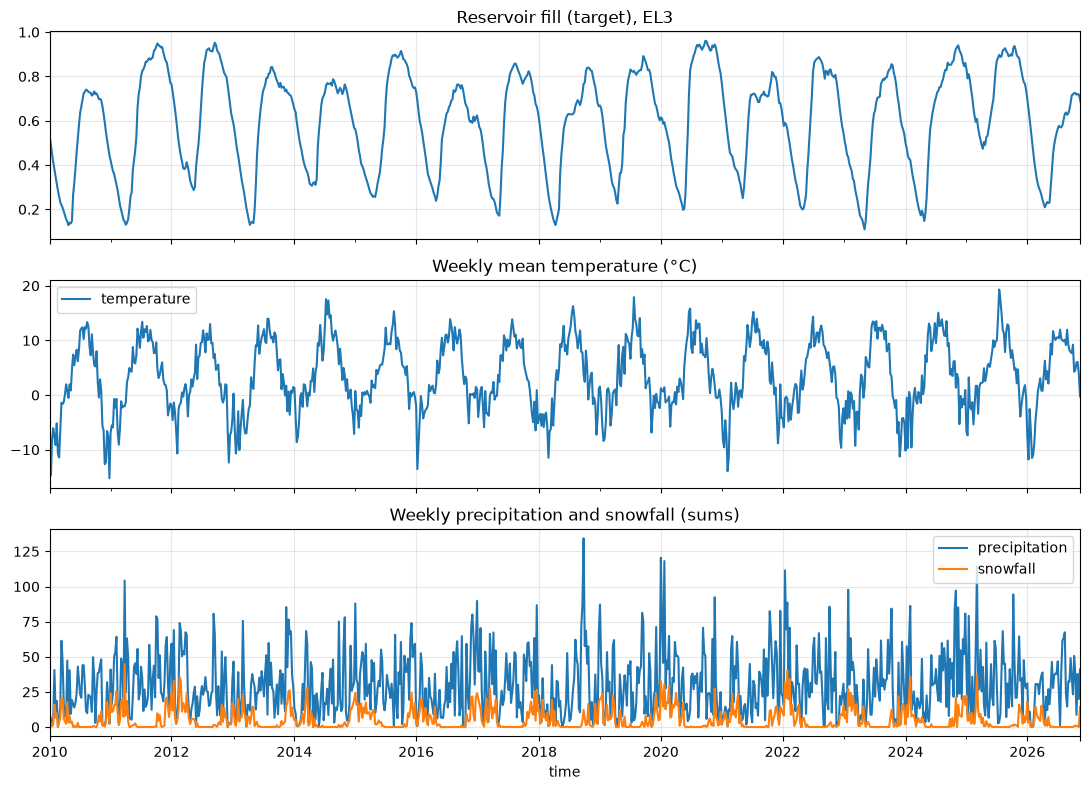

In [14]:
# Load target and exogenous sources for one area 
AREA_TYPE, AREA_NR = "EL", 3          # NO3, as in the earlier parts. Change freely (EL 1-5, VASS 1-3).
DATA_START = "2010-01-01"             # start of the weather/currency history (the target goes further back)

NVE_ANCHOR = detect_nve_anchor(nve)   # same value as in section 3.1
y_week = make_fill_series(nve, AREA_TYPE, AREA_NR, anchor=NVE_ANCHOR)
exog_week = build_exog_sources(AREA_TYPE, AREA_NR, start=DATA_START, anchor=NVE_ANCHOR)

print(f"Target {y_week.name}: {len(y_week)} weekly values, {y_week.index.min().date()} -> {y_week.index.max().date()}")
print("Value range (shows the unit, 0-1 or 0-100):", round(float(y_week.min()), 3), "-", round(float(y_week.max()), 3))
for name, df_ in exog_week.items():
    print(f"Exog '{name}': {df_.shape}, {df_.index.min().date()} -> {df_.index.max().date()}, "
          f"columns {list(df_.columns)}, NaN share {df_.isna().mean().mean():.3f}")

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
y_week.loc[DATA_START:].plot(ax=axes[0], title=f"Reservoir fill (target), {y_week.name}")
exog_week["weather"][["temperature"]].plot(ax=axes[1], title="Weekly mean temperature (°C)")
exog_week["weather"][["precipitation", "snowfall"]].plot(ax=axes[2], title="Weekly precipitation and snowfall (sums)")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 4.3 The forecast function

Structure of the code below

1. `build_exog_features` - lagged exogenous features for the training window **and** the future steps. Only data up to `train_end` is used; future weather is climatology, so there is **no leakage**.
2. `make_regressor` - builds the River regressor (linear model trained with SGD, or adaptive random forest).
3. `_run_snarimax` and `_run_lag_ml` - fit one model and return the forecast path (recursive / dynamic forecasting).
4. `forecast_fill` - the main function. Returns a `ForecastResult` with a forecast table (`forecast`, `lower`, `upper`).

**Parameters of `forecast_fill`**

| Group | Parameters |
|---|---|
| Data | `y`, `horizon`, `history` (number of recent steps used for training, `None` = all), `train_end`, `resolution` (`"W"`/`"M"`) |
| Model | `model` (`"snarimax"` or `"lag_ml"`) |
| SNARIMAX orders | `p, d, q` (non-seasonal), `sp, sd, sq` (seasonal, period `m`). Default `(3,0,1)(0,1,0)` = AR(3) + MA(1) after seasonal differencing |
| Lag-based ML | `lags`, `seasonal_terms`, `n_passes` (SNARIMAX learns in one pass because its lag buffer is part of the model state) |
| Regressor | `regressor` (`"linear"`/`"forest"`), `lr`, `l2`, `intercept_lr`, `n_trees` |
| Data sources | `exog` (dict), `exog_vars`, `exog_lags`, `future_rule` |
| Interval (bonus) | `interval`, `level` |

In [15]:
SEASON_LENGTH = {"W": 52, "M": 12}                         # seasonal period per resolution
DEFAULT_LAGS = {"W": (1, 2, 3, 4, 52), "M": (1, 2, 3, 12)}
DEFAULT_FUTURE_RULE = {"weather": "climatology", "currency": "last"}   # per exog source; others: 'last'


def to_resolution(obj, resolution: str):
    # Weekly data is returned unchanged; 'M' gives monthly means (month-end labels)
    if resolution == "W":
        return obj
    if resolution == "M":
        return obj.resample("ME").mean()
    raise ValueError("resolution must be 'W' or 'M'")


def _season_key(index: pd.DatetimeIndex, resolution: str) -> np.ndarray:
    # Week of year (1..52) or month (1..12): used for climatology and Fourier terms
    if resolution == "W":
        return np.minimum(index.isocalendar().week.to_numpy().astype(int), 52)
    return index.month.to_numpy()


def _fourier(index: pd.DatetimeIndex, resolution: str) -> list:
    # sin/cos seasonal terms (2 harmonics) as feature dicts, one per timestamp
    pos = _season_key(index, resolution) / SEASON_LENGTH[resolution]
    return [{"s1": np.sin(2 * np.pi * p), "c1": np.cos(2 * np.pi * p),
             "s2": np.sin(4 * np.pi * p), "c2": np.cos(4 * np.pi * p)} for p in pos]


def _future_values(known: pd.DataFrame, fut_index: pd.DatetimeIndex, rule: str, resolution: str) -> pd.DataFrame:
    # Values of an exogenous source for dates after the last known observation.
    #   'last'         : repeat the last known value
    #   'climatology'  : mean of the same week/month in all earlier years
    if rule == "last":
        return pd.DataFrame(np.tile(known.iloc[-1].to_numpy(), (len(fut_index), 1)),
                            index=fut_index, columns=known.columns)
    if rule == "climatology":
        clim = known.groupby(_season_key(known.index, resolution)).mean()
        vals = clim.reindex(_season_key(fut_index, resolution))
        vals.index = fut_index
        return vals.fillna(known.mean())                    # safety net for a week/month never seen
    raise ValueError("future_rule must be 'last' or 'climatology'")


def build_exog_features(exog: dict, exog_vars, exog_lags, hist_index, fut_index, train_end,
                        resolution="W", future_rule=None) -> pd.DataFrame:
    # Feature table (index = hist_index + fut_index) with one column per variable and lag.
    # Column names: 'temperature' (lag 0), 'temperature_lag4', ...
    # Values after `train_end` are never taken from the data, only from the rule (no leakage).
    rules = {**DEFAULT_FUTURE_RULE, **(future_rule or {})}
    all_index = hist_index.append(fut_index)
    wanted = {}                                            # source name -> list of columns
    for var in exog_vars:
        src = next((n for n, d in exog.items() if var in d.columns), None)
        if src is None:
            raise ValueError(f"Exogenous variable {var!r} not found. Available: "
                             f"{ {n: list(d.columns) for n, d in exog.items()} }")
        wanted.setdefault(src, []).append(var)

    pieces = []
    for src, cols in wanted.items():
        d = to_resolution(exog[src][cols], resolution).sort_index()
        known = d.loc[:train_end].dropna(how="any")
        if known.empty:
            raise ValueError(f"Source {src!r} has no data before train_end={train_end}")
        last_ok = known.index.max()                        # last real observation we may use
        ext = d.reindex(all_index)
        late = ext.index > last_ok                         # future AND not-yet-published days
        ext.loc[late] = _future_values(known, ext.index[late], rules.get(src, "last"), resolution).to_numpy()
        pieces.append(ext.interpolate(limit=4, limit_area="inside"))   # fill short internal holes
    base = pd.concat(pieces, axis=1)[list(exog_vars)]

    feats = {}
    for col in base.columns:
        for k in exog_lags:
            feats[col if k == 0 else f"{col}_lag{k}"] = base[col].shift(k)
    return pd.DataFrame(feats)


def make_regressor(kind="linear", lr=0.01, l2=0.0, intercept_lr=0.1, n_trees=10, seed=42, loss=None):
    # River regressor used by both models
    if kind == "linear":
        return preprocessing.StandardScaler() | linear_model.LinearRegression(
            optimizer=optim.SGD(lr), l2=l2, intercept_lr=intercept_lr,
            loss=loss if loss is not None else optim.losses.Squared())
    if kind == "forest":
        if loss is not None:
            raise ValueError("Quantile intervals need regressor='linear'")
        return forest.ARFRegressor(n_models=n_trees, seed=seed)
    raise ValueError("regressor must be 'linear' or 'forest'")

In [16]:
@dataclass
class ForecastResult:
    # Everything forecast_fill() returns
    forecast: pd.DataFrame          # index = forecast dates, columns forecast / lower / upper
    train_start: pd.Timestamp
    train_end: pd.Timestamp
    n_train: int
    model: str
    resolution: str
    settings: dict
    fit_seconds: float
    notes: list = field(default_factory=list)


def _run_snarimax(y_s, X_train, X_future, horizon, orders, regressor):
    # SNARIMAX (SARIMAX in River). One pass over the training data, then a dynamic multi-step forecast.
    model = time_series.SNARIMAX(regressor=regressor, **orders)
    for i, yi in enumerate(y_s):
        model.learn_one(yi, X_train[i] if X_train is not None else None)
    return np.asarray(model.forecast(horizon, xs=X_future), dtype=float)


def _run_lag_ml(y_s, X_train, X_future, fut_index, hist_index, resolution, lags, seasonal_terms,
                n_passes, regressor):
    # Lag-based ML: features = past values of y (+ exogenous + Fourier terms). Forecast is recursive:
    # each prediction is appended to the history and used as lag for the next step.
    max_lag = max(lags)
    four_h = _fourier(hist_index, resolution) if seasonal_terms else None
    four_f = _fourier(fut_index, resolution) if seasonal_terms else None

    def features(hist, i, x_exog, four):
        f = {f"y_lag{l}": hist[i - l] for l in lags}       # value l steps before position i
        if x_exog is not None:
            f.update(x_exog)
        if four is not None:
            f.update(four)
        return f

    for _ in range(n_passes):                               # several passes help the SGD models converge
        for i in range(max_lag, len(y_s)):
            regressor.learn_one(features(y_s, i, X_train[i] if X_train else None,
                                         four_h[i] if four_h else None), y_s[i])
    hist, out = list(y_s), []
    for h in range(len(fut_index)):
        pred = regressor.predict_one(features(hist, len(hist), X_future[h] if X_future else None,
                                              four_f[h] if four_f else None))
        hist.append(pred)
        out.append(pred)
    return np.asarray(out, dtype=float)

In [17]:
def forecast_fill(
    y: pd.Series,
    horizon: int = 26,
    history: int | None = 312,
    train_end=None,
    resolution: str = "W",
    model: str = "snarimax",
    # --- SNARIMAX orders: (p, d, q) non-seasonal, (sp, sd, sq) seasonal with period m
    # Default = SARIMA(3,0,1)(0,1,0)m: seasonal differencing (sd=1) removes the strong yearly cycle.
    # This is only a starting point; section 5 tests alternatives and the best one becomes the app default.
    p: int = 3, d: int = 0, q: int = 1, sp: int = 0, sd: int = 1, sq: int = 0, m: int | None = None,
    # --- lag-based ML
    lags: tuple | None = None, seasonal_terms: bool = True, n_passes: int = 3,
    # --- regressor settings (both models)
    regressor: str = "linear", lr: float = 0.01, l2: float = 0.0, intercept_lr: float = 0.1,
    n_trees: int = 10,
    # --- data sources
    exog: dict | None = None, exog_vars: tuple = (), exog_lags: tuple = (0,), future_rule: dict | None = None,
    # --- confidence interval (bonus): quantile regression
    interval: bool = False, level: float = 0.8,
    seed: int = 42,
) -> ForecastResult:
    # Forecast the next `horizon` steps of the fill of ONE area with River.
    #
    #  y          weekly fill series with a DatetimeIndex (see make_fill_series)
    #  horizon    number of steps ahead (weeks if resolution='W', months if 'M')
    #  history    number of most recent steps used for training (None = all)
    #  train_end  last date that may be used (default = end of y). Used for backtests.
    #  resolution 'W' (native) or 'M' (monthly means)
    #  model      'snarimax' | 'lag_ml'
    #  exog       {source: weekly DataFrame}; exog_vars picks columns, exog_lags the lags (in steps)
    #  future_rule  e.g. {'weather': 'climatology', 'currency': 'last'}
    #  interval   True -> also return `lower` and `upper` (quantile regression, level = 0.8 -> 10 %..90 %)
    t0 = time.perf_counter()
    notes = []

    # 0. Input checks 
    if horizon < 1:
        raise ValueError("horizon must be >= 1")
    if model not in ("snarimax", "lag_ml"):
        raise ValueError("model must be 'snarimax' or 'lag_ml'")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    if exog_vars and not exog:
        raise ValueError("exog_vars given but exog is empty")
    y = y.dropna().sort_index()
    if y.empty:
        raise ValueError("y has no data")
    m = m or SEASON_LENGTH[resolution]
    lags = tuple(lags) if lags else DEFAULT_LAGS[resolution]

    # 1. Training window 
    train_end = pd.Timestamp(train_end) if train_end is not None else y.index[-1]
    y_full = to_resolution(y.loc[:train_end], resolution)       # everything we are allowed to see
    y_tr = y_full.iloc[-history:] if history else y_full        # the part used for training
    freq = f"W-{y_tr.index[-1].day_name()[:3].upper()}" if resolution == "W" else "ME"
    fut_index = pd.date_range(y_tr.index[-1], periods=horizon + 1, freq=freq)[1:]

    # 2. Exogenous features (training rows and future rows) 
    X_all = None
    if exog_vars:
        # Features are built over the FULL history so that the first training rows still have their lags
        X_all = build_exog_features(exog, exog_vars, exog_lags, y_full.index, fut_index,
                                    y_full.index[-1], resolution, future_rule)
        ok = X_all.loc[y_tr.index].notna().all(axis=1)      # rows where every lagged feature exists
        if not ok.any():
            raise ValueError("No training rows with complete exogenous data. Check exog dates and lags.")
        first_ok = ok[ok].index[0]
        if first_ok > y_tr.index[0]:
            notes.append(f"training start moved to {first_ok.date()} (exogenous data starts later)")
            y_tr = y_tr.loc[first_ok:]
        if X_all.loc[y_tr.index].isna().any().any() or X_all.loc[fut_index].isna().any().any():
            raise ValueError("The exogenous data has gaps inside the training window. "
                             "Use a shorter history or fill the gaps first.")
        X_train = X_all.loc[y_tr.index].to_dict("records")
        X_future = X_all.loc[fut_index].to_dict("records")
    else:
        X_train = X_future = None

    needed = max(lags) + 20 if model == "lag_ml" else m * max(sp + sd, 1) + p + q + 10
    if len(y_tr) < needed:
        raise ValueError(f"Only {len(y_tr)} training steps, but at least {needed} are needed for these settings. "
                         "Use a longer history or smaller orders/lags.")

    #  3. Standardise the target 
    mu, sd_y = float(y_tr.mean()), float(y_tr.std()) or 1.0
    y_s = ((y_tr - mu) / sd_y).to_numpy()
    orders = dict(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq)

    def run(loss=None):
        reg = make_regressor(regressor, lr, l2, intercept_lr, n_trees, seed, loss)
        if model == "snarimax":
            return _run_snarimax(y_s, X_train, X_future, horizon, orders, reg)
        return _run_lag_ml(y_s, X_train, X_future, fut_index, y_tr.index, resolution, lags,
                           seasonal_terms, n_passes, reg)

    #  4. Fit and forecast 
    point = run()
    out = pd.DataFrame({"forecast": point * sd_y + mu}, index=fut_index)
    if interval:
        a = (1 - level) / 2
        out["lower"] = run(optim.losses.Quantile(a)) * sd_y + mu
        out["upper"] = run(optim.losses.Quantile(1 - a)) * sd_y + mu
        out["lower"] = np.minimum(out["lower"], out["forecast"])   # keep lower <= forecast <= upper
        out["upper"] = np.maximum(out["upper"], out["forecast"])
    else:
        out["lower"] = out["upper"] = np.nan

    #  5. Keep values inside the physical range (fill is 0..1 or 0..100) 
    top = 1.0 if float(y.max()) <= 1.0 else 100.0
    out = out.clip(lower=0.0, upper=top)
    if not np.isfinite(out["forecast"]).all():
        notes.append("WARNING: the model diverged (NaN/inf). Lower the learning rate `lr`.")

    settings = dict(horizon=horizon, history=history, resolution=resolution, model=model, p=p, d=d, q=q, sp=sp,
                    sd=sd, sq=sq, m=m, lags=lags, seasonal_terms=seasonal_terms, n_passes=n_passes,
                    regressor=regressor, lr=lr, l2=l2, intercept_lr=intercept_lr, n_trees=n_trees,
                    exog_vars=tuple(exog_vars), exog_lags=tuple(exog_lags), interval=interval, level=level)
    return ForecastResult(out, y_tr.index[0], y_tr.index[-1], len(y_tr), model, resolution, settings,
                          time.perf_counter() - t0, notes)

### 4.4 Smoke test: does the function run, with and without exogenous data?

This is only a quick functional test (one forecast from the newest data). A proper evaluation with several settings, walk-forward backtests and a seasonal-naive benchmark follows in section 5.

,training steps,seconds,first forecast,last forecast,notes
SNARIMAX,312,0.023,0.65,0.134,-
SNARIMAX + weather,312,0.048,0.663,0.126,-
lag_ml + weather,312,0.148,0.666,0.345,-


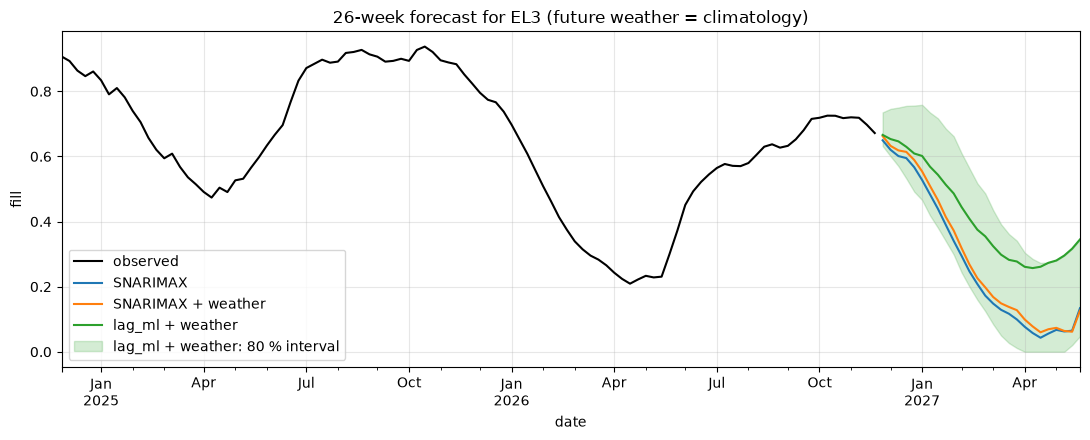

In [18]:
def plot_forecast(y, results: dict, last_n=104, title=None):
    # Plot the last `last_n` observed steps and one or more ForecastResult objects
    fig, ax = plt.subplots(figsize=(11, 4.5))
    y.iloc[-last_n:].plot(ax=ax, color="k", label="observed")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    for (name, r), c in zip(results.items(), colors):
        r.forecast["forecast"].plot(ax=ax, color=c, label=name)
        if r.forecast["lower"].notna().any():
            ax.fill_between(r.forecast.index, r.forecast["lower"], r.forecast["upper"], color=c, alpha=.2,
                            label=f"{name}: {int(r.settings['level'] * 100)} % interval")
    ax.set_title(title or f"Forecast of reservoir fill, {y.name}")
    ax.set_ylabel("fill")
    ax.legend()
    ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()


# Three variants: SNARIMAX alone, SNARIMAX + weather, lag-based ML + weather with an 80 % interval
runs = {
    "SNARIMAX": forecast_fill(y_week, horizon=26, history=312, model="snarimax"),
    "SNARIMAX + weather": forecast_fill(y_week, horizon=26, history=312, model="snarimax", exog=exog_week,
                                        exog_vars=("temperature", "precipitation", "snowfall"), exog_lags=(0, 4)),
    "lag_ml + weather": forecast_fill(y_week, horizon=26, history=312, model="lag_ml", exog=exog_week,
                                      exog_vars=("temperature", "snowfall"), exog_lags=(0, 4),
                                      interval=True, level=0.8),
}

summary = pd.DataFrame({
    name: {"training steps": r.n_train, "seconds": round(r.fit_seconds, 3),
           "first forecast": round(float(r.forecast["forecast"].iloc[0]), 3),
           "last forecast": round(float(r.forecast["forecast"].iloc[-1]), 3),
           "notes": "; ".join(r.notes) or "-"}
    for name, r in runs.items()
}).T
display(summary)
plot_forecast(y_week, runs, title=f"26-week forecast for {y_week.name} (future weather = climatology)")

### 4.5 Quick checks of the function itself

These cells check that the function reacts correctly to its inputs (they are not a quality test of the forecasts).

In [19]:
# 1) Forecast dates continue the weekly grid directly after the last training date
r = runs["SNARIMAX"]
assert r.forecast.index[0] == r.train_end + pd.Timedelta(days=7), "forecast does not start one week after the data"
assert (np.diff(r.forecast.index.values).astype("timedelta64[D]").astype(int) == 7).all()

# 2) train_end really hides later data (backtest use): same call, shorter data -> different forecast dates
r_old = forecast_fill(y_week, horizon=8, history=312, train_end=y_week.index[-60])
assert r_old.train_end == y_week.index[-60] and r_old.forecast.index[0] > y_week.index[-60]

# 3) Exogenous data after train_end must NOT change the result (no leakage)
exog_leak = {k: v.copy() for k, v in exog_week.items()}
exog_leak["weather"].loc[y_week.index[-59]:, "temperature"] += 50          # absurd values after train_end
a = forecast_fill(y_week, 8, 312, train_end=y_week.index[-60], exog=exog_week, exog_vars=("temperature",))
b = forecast_fill(y_week, 8, 312, train_end=y_week.index[-60], exog=exog_leak, exog_vars=("temperature",))
assert np.allclose(a.forecast["forecast"], b.forecast["forecast"]), "future exogenous data leaked into the forecast"

# 4) Readable errors for bad input
for bad in [dict(model="arima"), dict(horizon=0), dict(history=20), dict(exog_vars=("nonexistent",), exog=exog_week)]:
    try:
        forecast_fill(y_week, **{"horizon": 8, **bad})
        raise AssertionError(f"no error for {bad}")
    except ValueError as exc:
        print("OK, ValueError for", list(bad)[0], "->", str(exc)[:90])

# 5) Monthly resolution runs too (seasonal period 12)
r_m = forecast_fill(y_week, horizon=6, history=120, resolution="M")
print("\nMonthly forecast:", [str(d.date()) for d in r_m.forecast.index[:3]], "...", f"{r_m.fit_seconds:.3f} s")
print("All function checks passed.")

OK, ValueError for model -> model must be 'snarimax' or 'lag_ml'
OK, ValueError for horizon -> horizon must be >= 1
OK, ValueError for history -> Only 20 training steps, but at least 66 are needed for these settings. Use a longer histor
OK, ValueError for exog_vars -> Exogenous variable 'nonexistent' not found. Available: {'weather': ['temperature', 'precip

Monthly forecast: ['2026-12-31', '2027-01-31', '2027-02-28'] ... 0.018 s
All function checks passed.


## 5. Testing the forecast function for various settings

### 5.1 Method

One forecast cannot be judged. Reservoir filling is strongly seasonal, so a model can look good for a spring forecast and bad for an autumn one. The test therefore uses **walk-forward backtesting**:

* several **forecast origins** (default 6, spaced 13 weeks apart, so every season of the last ~1.5 years is covered);
* at each origin the model only sees data up to the origin (`train_end`), forecasts `horizon` weeks dynamically and is compared with what really happened;
* future weather is **not** the real weather (climatology is used), which is exactly the situation in the app;
* every setting is compared with a **seasonal-naive benchmark** ("same week last year"). A model that does not beat it is not useful;
* metrics: MAE and RMSE (fill units), bias, run time per forecast and, for interval models, the **coverage** of the nominal interval.

The settings are changed **one idea at a time** (history length, orders, learning rate, lag-ML options, data sources) so that the effect of each can be read from the table.

In [20]:
def seasonal_naive(y: pd.Series, dates: pd.DatetimeIndex, m: int, train_end: pd.Timestamp) -> np.ndarray:
    # Benchmark forecast: the value m steps earlier (never later than the end of the training data)
    pos = {t: i for i, t in enumerate(y.index)}
    out = []
    for t in dates:
        j = pos[t] - m
        out.append(y.iloc[j] if j >= 0 and y.index[j] <= train_end else np.nan)
    return np.asarray(out, dtype=float)


def backtest_forecast(y, horizon=26, n_origins=6, origin_step=13, **kw) -> pd.DataFrame:
    # Walk-forward test of forecast_fill(**kw). Returns one row per origin x forecast step.
    rows = []
    for k in reversed(range(n_origins)):
        end_pos = len(y) - horizon - k * origin_step          # number of points the model may see
        origin = y.index[end_pos - 1]
        res = forecast_fill(y, horizon=horizon, train_end=origin, **kw)
        fc = res.forecast.copy()
        fc["actual"] = y.reindex(fc.index).to_numpy()
        fc["naive"] = seasonal_naive(y, fc.index, kw.get("m") or SEASON_LENGTH["W"], origin)
        fc["origin"], fc["step"], fc["fit_seconds"] = origin, np.arange(1, horizon + 1), res.fit_seconds
        rows.append(fc)
    return pd.concat(rows)


def score(bt: pd.DataFrame) -> dict:
    # Summary metrics of one backtest
    e = bt["forecast"] - bt["actual"]
    has_naive = bt["naive"].notna()
    out = {"MAE": e.abs().mean(), "RMSE": float(np.sqrt((e ** 2).mean())), "bias": e.mean(),
           "naive_MAE": (bt.loc[has_naive, "naive"] - bt.loc[has_naive, "actual"]).abs().mean()}
    out["skill_vs_naive"] = 1 - out["MAE"] / out["naive_MAE"]        # > 0 means better than the benchmark
    out["sec_per_forecast"] = bt.groupby("origin")["fit_seconds"].first().mean()
    if bt["lower"].notna().any():
        inside = (bt["actual"] >= bt["lower"]) & (bt["actual"] <= bt["upper"])
        out["coverage"], out["mean_width"] = inside.mean(), (bt["upper"] - bt["lower"]).mean()
    return out


def evaluate_settings(y, settings, horizon=26, n_origins=6, origin_step=13, verbose=True) -> pd.DataFrame:
    # Run the backtest for a list of settings (dicts of forecast_fill arguments plus 'name' and 'group').
    # A failing setting is recorded in the 'error' column instead of stopping the whole test.
    rows = []
    for s in settings:
        kw = {k: v for k, v in s.items() if k not in ("name", "group")}
        row = {"name": s["name"], "group": s.get("group", "")}
        try:
            row.update(score(backtest_forecast(y, horizon, n_origins, origin_step, **kw)))
            row["error"] = ""
        except Exception as exc:
            row["error"] = str(exc)[:80]
        row["settings"] = {k: v for k, v in kw.items() if k != "exog"}      # exog tables are not stored
        rows.append(row)
        if verbose:
            print(f"{s['name']:42s} MAE {row.get('MAE', float('nan')):.4f}  {row['error']}")
    df = pd.DataFrame(rows)
    return df.sort_values("MAE").reset_index(drop=True) if "MAE" in df else df

### 5.2 Grid of settings

Every dictionary is simply a set of `forecast_fill()` arguments (plus a `name` and a `group` used for the report). Edit the list freely. The first setting of each model is the **base** that the exogenous settings are compared with.

In [21]:
EX = dict(exog=exog_week)                                       # the available exogenous sources
WX3 = ("temperature", "precipitation", "snowfall")              # weather set used in several settings
BASE_S, BASE_L = "SNARIMAX default (hist 312)", "lag_ml default (hist 312)"

SETTINGS = [
    #  history length 
    dict(name=BASE_S, group="history", model="snarimax", history=312),
    dict(name="SNARIMAX hist 104", group="history", model="snarimax", history=104),
    dict(name="SNARIMAX hist 156", group="history", model="snarimax", history=156),
    dict(name="SNARIMAX hist 520", group="history", model="snarimax", history=520),
    dict(name="SNARIMAX hist 1040", group="history", model="snarimax", history=1040),
    dict(name=BASE_L, group="history", model="lag_ml", history=312),
    dict(name="lag_ml hist 104", group="history", model="lag_ml", history=104),
    dict(name="lag_ml hist 520", group="history", model="lag_ml", history=520),
    #  SNARIMAX orders 
    dict(name="SNARIMAX p1 q0", group="orders", model="snarimax", history=312, p=1, q=0),
    dict(name="SNARIMAX p2 q1", group="orders", model="snarimax", history=312, p=2, q=1),
    dict(name="SNARIMAX p5 q1", group="orders", model="snarimax", history=312, p=5, q=1),
    dict(name="SNARIMAX seasonal AR (sp1 sd0)", group="orders", model="snarimax", history=312, sp=1, sd=0),
    dict(name="SNARIMAX sp1 sd1", group="orders", model="snarimax", history=312, sp=1, sd=1),
    dict(name="SNARIMAX d1 + sd1", group="orders", model="snarimax", history=312, d=1),
    #  learning rate (SGD) 
    dict(name="SNARIMAX lr 0.003", group="learning rate", model="snarimax", history=312, lr=0.003),
    dict(name="SNARIMAX lr 0.03", group="learning rate", model="snarimax", history=312, lr=0.03),
    dict(name="SNARIMAX lr 0.1", group="learning rate", model="snarimax", history=312, lr=0.1),
    dict(name="lag_ml lr 0.003", group="learning rate", model="lag_ml", history=312, lr=0.003),
    dict(name="lag_ml lr 0.03", group="learning rate", model="lag_ml", history=312, lr=0.03),
    #  lag-based ML options 
    dict(name="lag_ml lags 1,2,52", group="lag_ml options", model="lag_ml", history=312, lags=(1, 2, 52)),
    dict(name="lag_ml lags 1,2,3,4,8,13,26,52", group="lag_ml options", model="lag_ml", history=312,
         lags=(1, 2, 3, 4, 8, 13, 26, 52)),
    dict(name="lag_ml no seasonal terms", group="lag_ml options", model="lag_ml", history=312, seasonal_terms=False),
    dict(name="lag_ml 1 pass", group="lag_ml options", model="lag_ml", history=312, n_passes=1),
    dict(name="lag_ml 10 passes", group="lag_ml options", model="lag_ml", history=312, n_passes=10),
    dict(name="lag_ml random forest", group="lag_ml options", model="lag_ml", history=312, regressor="forest"),
    #  data sources (exogenous variables) 
    dict(name="SNARIMAX + temperature", group="exogenous", model="snarimax", history=312,
         exog_vars=("temperature",), **EX),
    dict(name="SNARIMAX + weather (lag 0)", group="exogenous", model="snarimax", history=312, exog_vars=WX3, **EX),
    dict(name="SNARIMAX + weather (lags 0,4,8)", group="exogenous", model="snarimax", history=312,
         exog_vars=WX3, exog_lags=(0, 4, 8), **EX),
    dict(name="SNARIMAX + currency (EURNOK)", group="exogenous", model="snarimax", history=312,
         exog_vars=("EURNOK",), **EX),
    dict(name="SNARIMAX + weather + currency", group="exogenous", model="snarimax", history=312,
         exog_vars=WX3 + ("EURNOK",), exog_lags=(0, 4), **EX),
    dict(name="lag_ml + weather (lags 0,4)", group="exogenous", model="lag_ml", history=312,
         exog_vars=WX3, exog_lags=(0, 4), **EX),
    dict(name="lag_ml + weather (lags 0,4,8)", group="exogenous", model="lag_ml", history=312,
         exog_vars=WX3, exog_lags=(0, 4, 8), **EX),
    dict(name="lag_ml + currency (EURNOK)", group="exogenous", model="lag_ml", history=312,
         exog_vars=("EURNOK",), **EX),
    dict(name="lag_ml forest + weather", group="exogenous", model="lag_ml", history=312, regressor="forest",
         exog_vars=WX3, exog_lags=(0, 4), **EX),
]

HORIZON, N_ORIGINS, ORIGIN_STEP = 26, 6, 13
print(f"{len(SETTINGS)} settings x {N_ORIGINS} origins x {HORIZON}-week horizon\n")
results = evaluate_settings(y_week, SETTINGS, HORIZON, N_ORIGINS, ORIGIN_STEP)

34 settings x 6 origins x 26-week horizon

SNARIMAX default (hist 312)                MAE 0.0996  
SNARIMAX hist 104                          MAE 0.0981  
SNARIMAX hist 156                          MAE 0.1041  
SNARIMAX hist 520                          MAE 0.1077  
SNARIMAX hist 1040                         MAE 0.1112  
lag_ml default (hist 312)                  MAE 0.0823  
lag_ml hist 104                            MAE 0.1426  
lag_ml hist 520                            MAE 0.0991  
SNARIMAX p1 q0                             MAE 0.1081  
SNARIMAX p2 q1                             MAE 0.1029  
SNARIMAX p5 q1                             MAE 0.1009  
SNARIMAX seasonal AR (sp1 sd0)             MAE 0.1592  
SNARIMAX sp1 sd1                           MAE 0.0859  
SNARIMAX d1 + sd1                          MAE 0.1358  
SNARIMAX lr 0.003                          MAE 0.1238  
SNARIMAX lr 0.03                           MAE 0.1006  
SNARIMAX lr 0.1                            MAE 0.4745  
lag_m

,name,group,MAE,RMSE,bias,skill_vs_naive,sec_per_forecast,error
0,lag_ml + currency (EURNOK),exogenous,0.0814,0.0928,0.0696,0.5753,0.0416,
1,lag_ml default (hist 312),history,0.0823,0.0925,0.0673,0.5709,0.0305,
2,lag_ml 1 pass,lag_ml options,0.0824,0.0972,0.0689,0.5699,0.0173,
3,SNARIMAX sp1 sd1,orders,0.0859,0.1066,0.0688,0.5521,0.0127,
4,lag_ml 10 passes,lag_ml options,0.0860,0.1027,0.0689,0.5513,0.0915,
5,"lag_ml lags 1,2,52",lag_ml options,0.0861,0.1001,0.0801,0.5506,0.0306,
6,lag_ml lr 0.003,learning rate,0.0908,0.1090,0.0819,0.5263,0.0345,
7,SNARIMAX hist 104,history,0.0981,0.1272,0.0819,0.4882,0.0068,
8,lag_ml hist 520,history,0.0991,0.1091,0.0800,0.4832,0.0517,
9,SNARIMAX default (hist 312),history,0.0996,0.1311,0.0709,0.4804,0.0126,


Seasonal-naive benchmark MAE: 0.1917


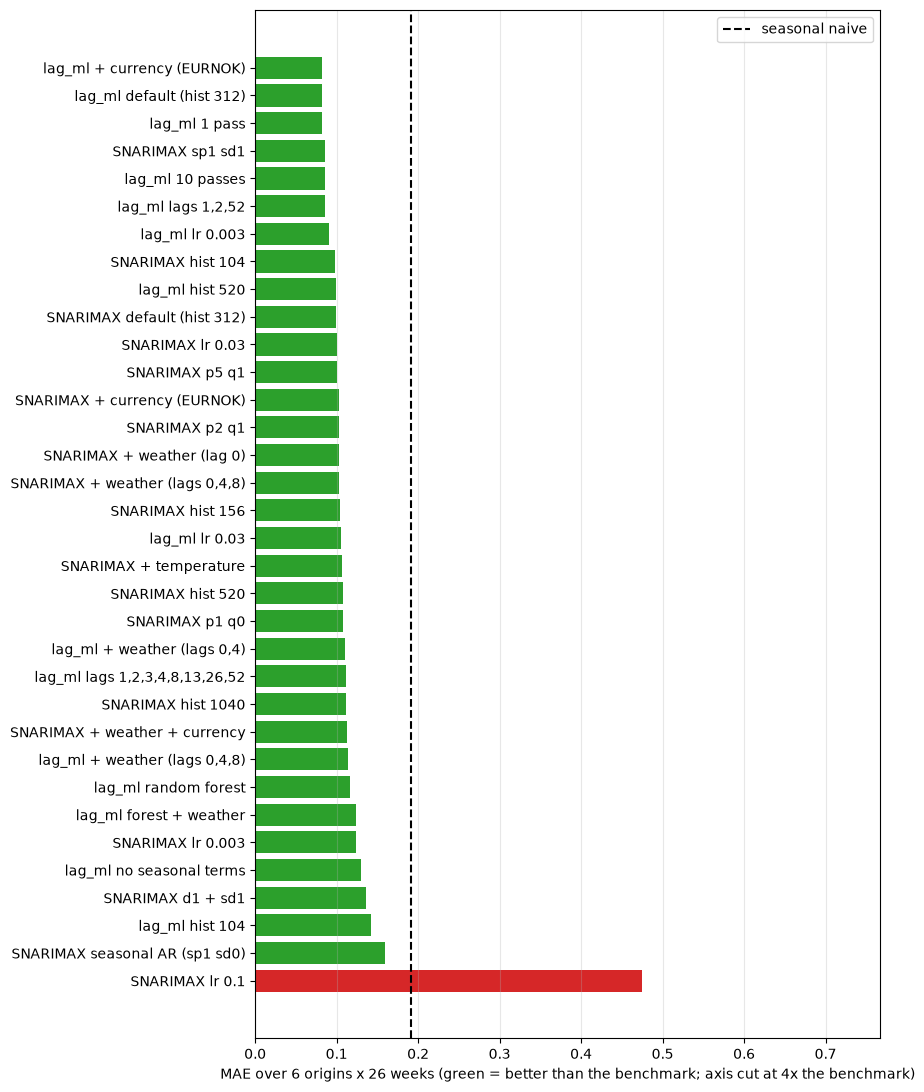

In [22]:
#  Result table (sorted by MAE; lower is better) 
show_cols = ["name", "group", "MAE", "RMSE", "bias", "skill_vs_naive", "sec_per_forecast", "error"]
display(results[show_cols].round(4))
print("Seasonal-naive benchmark MAE:", round(float(results["naive_MAE"].dropna().iloc[0]), 4))

#  Plot: MAE of every setting against the benchmark 
ok = results.dropna(subset=["MAE"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.28 * len(ok) + 1.5))
ax.barh(ok["name"], ok["MAE"], color=np.where(ok["skill_vs_naive"] > 0, "tab:green", "tab:red"))
ax.axvline(ok["naive_MAE"].iloc[0], color="k", ls="--", label="seasonal naive")
ax.set_xlim(0, 4 * ok["naive_MAE"].iloc[0])             # very bad settings are cut off so the others stay readable
ax.set_xlabel(f"MAE over {N_ORIGINS} origins x {HORIZON} weeks (green = better than the benchmark; axis cut at 4x the benchmark)")
ax.legend()
ax.grid(alpha=.3, axis="x")
plt.tight_layout()
plt.show()

### 5.3 Time resolution: weekly or monthly?

Weekly is the native resolution of the target. A monthly model has seasonal period 12 instead of 52 and about 4 times fewer training points, so it should be faster, but it throws information away. Both are scored on the **same quantity**: monthly means over the months that lie completely inside the forecast window.

In [23]:
def compare_resolutions(y_w, horizon_weeks=26, n_origins=6, origin_step=13, **common):
    # Score weekly and monthly models on monthly means of the months fully inside the forecast window.
    #   common : forecast_fill arguments used for both (model, regressor, lr, ...)
    y_month_actual = y_w.resample("ME").mean()
    rows = []
    for k in reversed(range(n_origins)):
        origin = y_w.index[len(y_w) - horizon_weeks - k * origin_step - 1]

        # weekly model -> monthly means
        t0 = time.perf_counter()
        rw = forecast_fill(y_w, horizon_weeks, history=312, train_end=origin, **common)
        t_w = time.perf_counter() - t0
        fw = rw.forecast["forecast"].resample("ME").mean()

        # monthly model on monthly means of complete months up to the origin
        ym = y_w.loc[:origin].resample("ME").mean()
        ym = ym[ym.index <= origin]
        t0 = time.perf_counter()
        rm = forecast_fill(ym, int(np.ceil(horizon_weeks / 4.345)) + 1, history=72, resolution="M", **common)
        t_m = time.perf_counter() - t0
        fm = rm.forecast["forecast"]

        # months that start after the origin and end inside the weekly forecast window
        last_day = rw.forecast.index[-1]
        months = [d for d in fw.index if d.to_period("M").start_time > origin and d <= last_day and d in fm.index
                  and d in y_month_actual.index]
        for d in months:
            rows.append({"origin": origin, "month": d, "actual": y_month_actual[d], "weekly": fw[d], "monthly": fm[d],
                         "sec_weekly": t_w, "sec_monthly": t_m})
    cmp_ = pd.DataFrame(rows)
    summary = pd.DataFrame({
        "MAE on monthly means": [(cmp_["weekly"] - cmp_["actual"]).abs().mean(), (cmp_["monthly"] - cmp_["actual"]).abs().mean()],
        "seconds per forecast": [cmp_["sec_weekly"].mean(), cmp_["sec_monthly"].mean()],
        "months scored": [len(cmp_), len(cmp_)],
    }, index=["weekly model", "monthly model"])
    return summary


res_rows = {}
for mdl in ("snarimax", "lag_ml"):
    res_rows[mdl] = compare_resolutions(y_week, HORIZON, N_ORIGINS, ORIGIN_STEP, model=mdl)
resolution_results = pd.concat(res_rows, names=["model", "resolution"])
display(resolution_results.round(4))

MAE on monthly means  seconds per forecast  months scored
model    resolution                                                              
snarimax weekly model                 0.0854                0.0140             30
         monthly model                0.1653                0.0131             30
lag_ml   weekly model                 0.0761                0.0283             30
         monthly model                0.1511                0.0122             30

### 5.4 Confidence intervals (bonus: `optim.losses.Quantile`)

`interval=True` trains the same model two more times with `optim.losses.Quantile(alpha)` as the loss of the linear regressor (`alpha` = 0.1 and 0.9 for an 80 % interval). The test checks whether the interval is **calibrated**: the share of true values inside the band (`coverage`) should be close to the nominal 80 %. A much lower share means the interval is over-confident.

In [24]:
INTERVAL_SETTINGS = [
    dict(name="SNARIMAX interval 80 %", group="interval", model="snarimax", history=312, interval=True, level=0.8),
    dict(name="lag_ml interval 80 %", group="interval", model="lag_ml", history=312, interval=True, level=0.8),
    dict(name="lag_ml + weather interval 80 %", group="interval", model="lag_ml", history=312, exog_vars=WX3,
         exog_lags=(0, 4), interval=True, level=0.8, **EX),
]
interval_results = evaluate_settings(y_week, INTERVAL_SETTINGS, HORIZON, N_ORIGINS, ORIGIN_STEP, verbose=False)
display(interval_results[["name", "MAE", "coverage", "mean_width", "sec_per_forecast", "error"]].round(4))
print("Nominal coverage: 0.80")

,name,MAE,coverage,mean_width,sec_per_forecast,error
0,lag_ml interval 80 %,0.0823,0.5256,0.2206,0.0881,
1,SNARIMAX interval 80 %,0.0996,0.7821,0.3823,0.0300,
2,lag_ml + weather interval 80 %,0.1105,0.4679,0.2214,0.1400,


Nominal coverage: 0.80


### 5.5 The chosen default setting

The best **point-forecast** setting (lowest MAE in `results`) becomes the default of the Streamlit forecasting page. It is written to `config/forecast_defaults.json`, which the app reads, so notebook and app always agree. If no setting beats the seasonal-naive benchmark, the best one is still stored, and the findings below say so.

The interval is switched on in the default when the best model uses the linear regressor (quantile loss does not work with the random forest).

Best setting: lag_ml + currency (EURNOK) | MAE 0.0814 | skill vs seasonal naive 0.575
Saved config\forecast_defaults.json
{
 "model": "lag_ml",
 "history": 312,
 "exog_vars": [
  "EURNOK"
 ],
 "interval": true,
 "level": 0.8
}


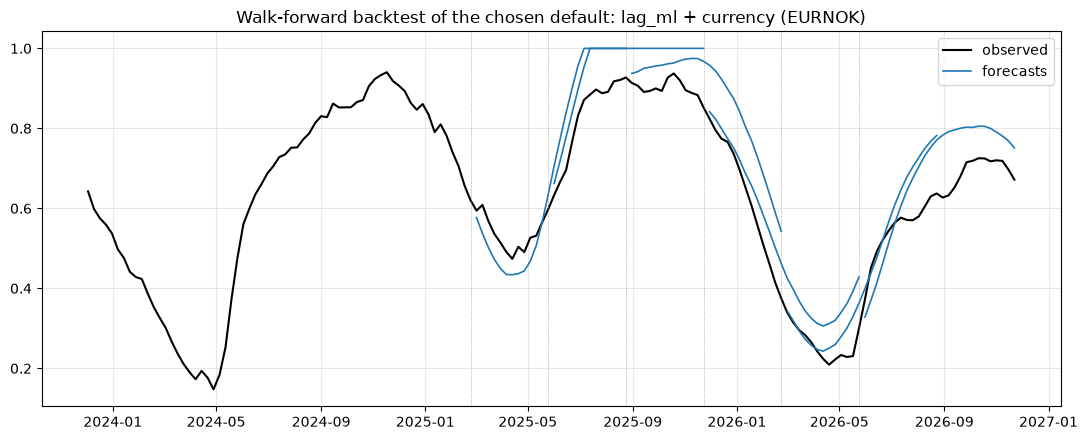

In [25]:
best_row = results.dropna(subset=["MAE"]).iloc[0]
best_settings = dict(best_row["settings"])
print("Best setting:", best_row["name"], "| MAE", round(best_row["MAE"], 4),
      "| skill vs seasonal naive", round(best_row["skill_vs_naive"], 3))
if best_row["skill_vs_naive"] <= 0:
    print("WARNING: the best setting does not beat the seasonal-naive benchmark - say this in the findings.")


def to_jsonable(obj):
    # numpy types and tuples -> plain JSON types
    if isinstance(obj, dict):
        return {k: to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    return obj


interval_ok = best_settings.get("regressor", "linear") == "linear"
DEFAULTS = {
    "name": best_row["name"], "area_type": AREA_TYPE, "area_nr": AREA_NR, "resolution": "W",
    "settings": to_jsonable({**best_settings, "interval": interval_ok, "level": 0.8}),
    "metrics": {k: float(best_row[k]) for k in ["MAE", "RMSE", "naive_MAE", "skill_vs_naive", "sec_per_forecast"]},
    "created": date.today().isoformat(),
}
cfg_path = ROOT / "config" / "forecast_defaults.json"
cfg_path.parent.mkdir(exist_ok=True)
cfg_path.write_text(json.dumps(DEFAULTS, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", cfg_path.relative_to(ROOT))
print(json.dumps(DEFAULTS["settings"], indent=1)[:600])

#  Plot: the backtest of the chosen setting - every origin against what really happened 
kw_best = {**best_settings, "interval": False}
if best_settings.get("exog_vars"):
    kw_best["exog"] = exog_week
bt_best = backtest_forecast(y_week, HORIZON, N_ORIGINS, ORIGIN_STEP, **kw_best)
fig, ax = plt.subplots(figsize=(11, 4.5))
obs = y_week.iloc[-(HORIZON + N_ORIGINS * ORIGIN_STEP + 52):]
ax.plot(obs.index, obs.values, color="k", lw=1.5, label="observed")
for i, (origin, g) in enumerate(bt_best.groupby("origin")):
    ax.plot(g.index, g["forecast"], lw=1.2, label="forecasts" if i == 0 else None, color="tab:blue")
    ax.axvline(origin, color="grey", lw=.5, ls=":")
ax.set_title(f"Walk-forward backtest of the chosen default: {best_row['name']}")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 5.6 Findings (generated from the results above)

The text below is **built from the tables of this run**, so it always matches the numbers. 

In [26]:
def make_findings(results, resolution_results, interval_results, horizon, n_origins, step):
    ok = results.dropna(subset=["MAE"])
    best, naive = ok.iloc[0], float(ok["naive_MAE"].iloc[0])
    L = []
    L.append(f"**How it was tested.** Walk-forward backtest with {n_origins} forecast origins spaced {step} weeks apart "
             f"and a {horizon}-week horizon; future weather = climatology; benchmark = seasonal naive "
             f"(MAE {naive:.4f}). {len(ok)} of {len(results)} settings ran without error.")
    n_beat = int((ok["skill_vs_naive"] > 0).sum())
    L.append(f"**Benchmark.** {n_beat} of {len(ok)} settings beat the seasonal-naive forecast. The best, "
             f"*{best['name']}*, has MAE {best['MAE']:.4f} ({best['skill_vs_naive'] * 100:+.0f} % vs the benchmark) "
             f"and takes {best['sec_per_forecast']:.2f} s per forecast.")
    for grp, text in [("history", "History length"), ("orders", "SNARIMAX orders"), ("learning rate", "Learning rate"),
                      ("lag_ml options", "Lag-ML options")]:
        g = ok[ok["group"] == grp]
        if len(g) > 1:
            b, w = g.iloc[0], g.iloc[-1]
            L.append(f"**{text}.** Best: *{b['name']}* (MAE {b['MAE']:.4f}); worst: *{w['name']}* (MAE {w['MAE']:.4f}).")
    # exogenous sources compared with the same model WITHOUT exogenous data (same regressor)
    def base_name(settings):
        if settings["model"] == "snarimax":
            return BASE_S
        return "lag_ml random forest" if settings.get("regressor") == "forest" else BASE_L

    ex = ok[ok["group"] == "exogenous"]
    parts = []
    for _, r in ex.iterrows():
        b = ok.loc[ok["name"] == base_name(r["settings"]), "MAE"]
        if len(b):
            parts.append(f"{r['name']}: {100 * (r['MAE'] / float(b.iloc[0]) - 1):+.0f} %")
    if parts:
        L.append("**Exogenous data** (change in MAE relative to the same model and regressor without it; negative = better): "
                 + "; ".join(parts) + ". Future weather is unknown and replaced by climatology, which limits what "
                 "weather can add beyond the first weeks.")
    for mdl in resolution_results.index.get_level_values(0).unique():
        r = resolution_results.loc[mdl]
        L.append(f"**Resolution ({mdl}).** Weekly MAE {r.loc['weekly model', 'MAE on monthly means']:.4f} in "
                 f"{r.loc['weekly model', 'seconds per forecast']:.3f} s; monthly MAE "
                 f"{r.loc['monthly model', 'MAE on monthly means']:.4f} in {r.loc['monthly model', 'seconds per forecast']:.3f} s.")
    iv = interval_results.dropna(subset=["coverage"])
    if len(iv):
        L.append("**Intervals (nominal 80 %).** " + "; ".join(
            f"{r['name']}: coverage {r['coverage'] * 100:.0f} %, mean width {r['mean_width']:.3f}" for _, r in iv.iterrows()) + ".")
    L.append("**Caution.** With only a few origins, differences of a few percent between settings are within the noise; "
             "treat clear gaps as findings and small gaps as ties.")
    return "\n\n".join(L)


from IPython.display import Markdown
FINDINGS_TEXT = make_findings(results, resolution_results, interval_results, HORIZON, N_ORIGINS, ORIGIN_STEP)
display(Markdown(FINDINGS_TEXT))

**How it was tested.** Walk-forward backtest with 6 forecast origins spaced 13 weeks apart and a 26-week horizon; future weather = climatology; benchmark = seasonal naive (MAE 0.1917). 34 of 34 settings ran without error.

**Benchmark.** 33 of 34 settings beat the seasonal-naive forecast. The best, *lag_ml + currency (EURNOK)*, has MAE 0.0814 (+58 % vs the benchmark) and takes 0.04 s per forecast.

**History length.** Best: *lag_ml default (hist 312)* (MAE 0.0823); worst: *lag_ml hist 104* (MAE 0.1426).

**SNARIMAX orders.** Best: *SNARIMAX sp1 sd1* (MAE 0.0859); worst: *SNARIMAX seasonal AR (sp1 sd0)* (MAE 0.1592).

**Learning rate.** Best: *lag_ml lr 0.003* (MAE 0.0908); worst: *SNARIMAX lr 0.1* (MAE 0.4745).

**Lag-ML options.** Best: *lag_ml 1 pass* (MAE 0.0824); worst: *lag_ml no seasonal terms* (MAE 0.1295).

**Exogenous data** (change in MAE relative to the same model and regressor without it; negative = better): lag_ml + currency (EURNOK): -1 %; SNARIMAX + currency (EURNOK): +3 %; SNARIMAX + weather (lag 0): +4 %; SNARIMAX + weather (lags 0,4,8): +4 %; SNARIMAX + temperature: +7 %; lag_ml + weather (lags 0,4): +34 %; SNARIMAX + weather + currency: +14 %; lag_ml + weather (lags 0,4,8): +39 %; lag_ml forest + weather: +6 %. Future weather is unknown and replaced by climatology, which limits what weather can add beyond the first weeks.

**Resolution (snarimax).** Weekly MAE 0.0854 in 0.014 s; monthly MAE 0.1653 in 0.013 s.

**Resolution (lag_ml).** Weekly MAE 0.0761 in 0.028 s; monthly MAE 0.1511 in 0.012 s.

**Intervals (nominal 80 %).** lag_ml interval 80 %: coverage 53 %, mean width 0.221; SNARIMAX interval 80 %: coverage 78 %, mean width 0.382; lag_ml + weather interval 80 %: coverage 47 %, mean width 0.221.

**Caution.** With only a few origins, differences of a few percent between settings are within the noise; treat clear gaps as findings and small gaps as ties.

### 5.7 Shared module for the Streamlit app

The Streamlit page must use **exactly** the same code as this notebook. The functions of section 4.3 are therefore also stored in `utils/forecasting.py` (delivered together with this notebook, together with `load_defaults()` that reads `config/forecast_defaults.json`). The cell checks that both give the same forecast.

In [30]:
import sys
module_path = ROOT / "utils" / "forecasting.py"
if not module_path.exists():
    print("utils/forecasting.py not found - copy it into the project to run this check.")
else:
    sys.path.insert(0, str(ROOT))
    import importlib
    import utils.forecasting as fmod
    importlib.reload(fmod)
    kw = dict(horizon=13, history=312, model="lag_ml", exog_vars=("temperature",), exog_lags=(0, 4))
    a = forecast_fill(y_week, exog=exog_week, **kw).forecast["forecast"]
    b = fmod.forecast_fill(y_week, exog=exog_week, **kw).forecast["forecast"]
    assert np.allclose(a, b), "module and notebook give different forecasts"
    print("OK: utils/forecasting.py gives the same forecast as the notebook.")
    app_kwargs = fmod.load_defaults()                      # what the Streamlit page will start with
    print("Default settings for the app:", {k: app_kwargs[k] for k in list(app_kwargs)[:6]}, "...")

OK: utils/forecasting.py gives the same forecast as the notebook.
Default settings for the app: {'resolution': 'W', 'model': 'lag_ml', 'history': 312, 'exog_vars': ('EURNOK',), 'interval': True, 'level': 0.8} ...


## 6. Sliding-window correlation: meteorology and Magasinstatistikk

**Question:** which weather property is correlated with the reservoir filling, with what delay (lag), and is the correlation stable in time? The sliding-window function is the notebook version of what the Streamlit page will offer with selectable lag and window length.

**Design**

* `sliding_correlation(x, y, window, lag)` = Pearson correlation of `x` shifted `lag` weeks **back in time** and `y`, inside a rolling window of `window` weeks. Lag > 0 means *the weather comes first* - the only direction that is useful for prediction.
* The representative Magasinstatistikk variable is the **weekly change in fill** (`fill.diff()`).
* Weather and fill both follow the seasons, so a correlation of the raw series mostly measures *"both are seasonal"*. The analysis therefore also uses **anomalies** (value minus the average of the same week of the year). Section 6.1 shows the difference.

Temperature vs fill LEVEL (raw, lag 0):              r = +0.39   <- mostly the shared seasonal cycle
Temperature anomaly vs fill-change anomaly (lag 0):  r = +0.40   <- what is left after removing the seasons


,temperature,precipitation,snowfall,wind
lag (weeks),,,,
0,0.40,0.42,0.18,0.26
1,0.22,0.13,0.03,0.07
2,0.01,0.05,0.03,-0.01
3,-0.04,0.07,0.04,-0.00
4,-0.05,0.04,0.05,0.04
5,-0.09,0.02,0.08,0.01
6,-0.11,-0.07,-0.02,-0.08
7,-0.12,-0.04,-0.04,-0.07
8,-0.16,-0.08,-0.08,-0.07


Strongest lag per weather variable: {'temperature': (0, 0.4), 'precipitation': (0, 0.42), 'snowfall': (0, 0.18), 'wind': (0, 0.26)}


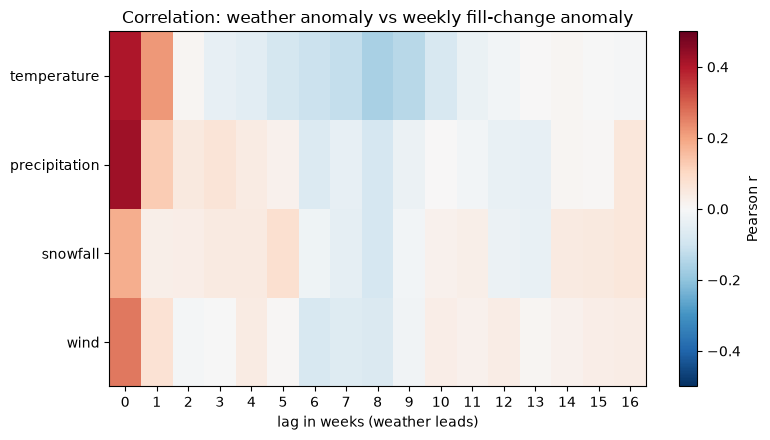

In [31]:
def weekly_anomaly(s: pd.Series) -> pd.Series:
    # Value minus the mean of the same week of the year = the seasonal cycle is removed
    return s - s.groupby(_season_key(s.index, "W")).transform("mean")


def sliding_correlation(x: pd.Series, y: pd.Series, window: int = 26, lag: int = 0) -> pd.Series:
    # Rolling Pearson correlation between x(t - lag) and y(t) over `window` weeks
    return x.shift(lag).rolling(window).corr(y)


weather_w = exog_week["weather"]
fill_w = y_week.loc[weather_w.index.min():]
d_fill = fill_w.diff().dropna()                                  # weekly change of the fill
anom_fill = weekly_anomaly(d_fill)
anom_wx = weather_w.apply(weekly_anomaly)

#  6.1 Raw series versus anomalies 
raw_r = weather_w["temperature"].corr(fill_w)
anom_r = anom_wx["temperature"].corr(anom_fill)
print(f"Temperature vs fill LEVEL (raw, lag 0):              r = {raw_r:+.2f}   <- mostly the shared seasonal cycle")
print(f"Temperature anomaly vs fill-change anomaly (lag 0):  r = {anom_r:+.2f}   <- what is left after removing the seasons")

#  6.2 Correlation at different lags (whole period) 
LAGS = list(range(0, 17))
lag_table = pd.DataFrame({v: [anom_wx[v].shift(L).corr(anom_fill) for L in LAGS] for v in anom_wx.columns}, index=LAGS)
lag_table.index.name = "lag (weeks)"
best_lag = lag_table.abs().idxmax()
display(lag_table.round(2))
print("Strongest lag per weather variable:", {v: (int(best_lag[v]), round(float(lag_table.loc[best_lag[v], v]), 2))
                                              for v in lag_table.columns})

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(lag_table.T, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(LAGS)), LAGS)
ax.set_yticks(range(lag_table.shape[1]), lag_table.columns)
ax.set_xlabel("lag in weeks (weather leads)")
ax.set_title("Correlation: weather anomaly vs weekly fill-change anomaly")
fig.colorbar(im, label="Pearson r")
plt.tight_layout()
plt.show()

Focus: precipitation, lag 0 weeks


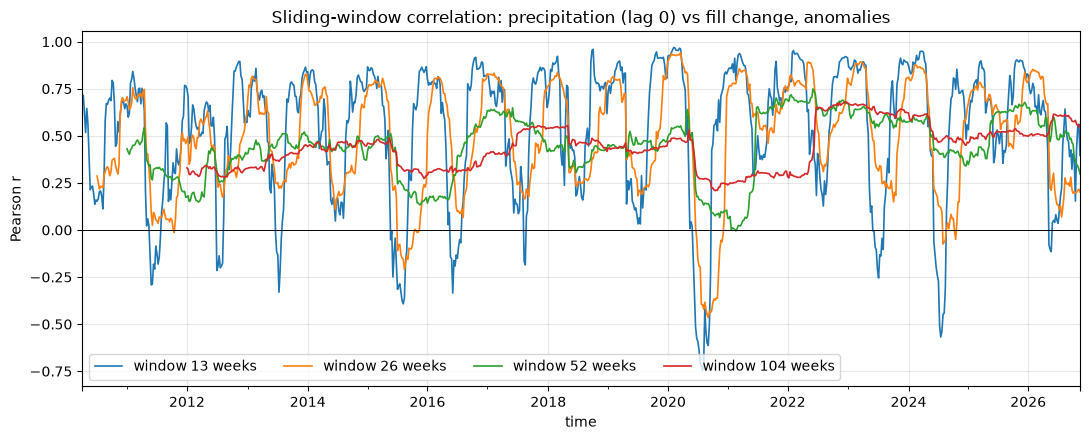

,mean r,min r,max r,share of windows with the opposite sign
window (weeks),,,,
13,0.53,-0.75,0.97,0.10
26,0.49,-0.47,0.94,0.06
52,0.45,-0.00,0.75,0.00
104,0.44,0.21,0.68,0.00


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"r per year (precipitation, lag 0)",0.44,0.17,0.41,0.5,0.37,0.17,0.6,0.46,0.43,0.47,0.11,0.69,0.67,0.57,0.37,0.65,0.3


In [32]:
#  6.3 Sliding windows: does the correlation change in time? 
focus_var = lag_table.abs().max().idxmax()                       # the weather variable with the strongest link
focus_lag = int(best_lag[focus_var])
print(f"Focus: {focus_var}, lag {focus_lag} weeks")

WINDOWS = (13, 26, 52, 104)
fig, ax = plt.subplots(figsize=(11, 4.5))
stability = []
for w in WINDOWS:
    r_t = sliding_correlation(anom_wx[focus_var], anom_fill, window=w, lag=focus_lag).dropna()
    r_t.plot(ax=ax, lw=1.2, label=f"window {w} weeks")
    overall = anom_wx[focus_var].shift(focus_lag).corr(anom_fill)
    stability.append({"window (weeks)": w, "mean r": r_t.mean(), "min r": r_t.min(), "max r": r_t.max(),
                      "share of windows with the opposite sign": float((np.sign(r_t) != np.sign(overall)).mean())})
ax.axhline(0, color="k", lw=.7)
ax.set_title(f"Sliding-window correlation: {focus_var} (lag {focus_lag}) vs fill change, anomalies")
ax.set_ylabel("Pearson r")
ax.legend(ncol=4)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()
stability = pd.DataFrame(stability).set_index("window (weeks)")
display(stability.round(2))

#  6.4 Year by year (52-week windows ending in December) 
yearly = (pd.DataFrame({"x": anom_wx[focus_var].shift(focus_lag), "y": anom_fill}).dropna()
          .groupby(lambda d: d.year).apply(lambda g: g["x"].corr(g["y"])))
yearly.name = f"r per year ({focus_var}, lag {focus_lag})"
display(yearly.round(2).to_frame().T)

In [33]:
#  6.5 Findings written from the numbers above 
v_best = lag_table.abs().max().sort_values(ascending=False)
sign = "positive" if lag_table.loc[focus_lag, focus_var] > 0 else "negative"
r_max = float(lag_table.abs().max().max())
strength = "weak" if r_max < 0.2 else "moderate" if r_max < 0.5 else "strong"
swing = stability.loc[52, "max r"] - stability.loc[52, "min r"]
yr_pos, yr_neg = int((yearly > 0).sum()), int((yearly < 0).sum())
COR_FINDINGS = (
    f"**Raw versus anomalies.** The raw correlation between temperature and the fill level is r = {raw_r:+.2f}, but it is mostly "
    f"the shared seasonal cycle. After removing the seasons the correlation with the weekly change is r = {anom_r:+.2f} at lag 0.\n\n"
    f"**Which variable and which lag.** The strongest link to the weekly fill change is *{focus_var}* at a lag of "
    f"{focus_lag} weeks ({sign}, r = {lag_table.loc[focus_lag, focus_var]:+.2f}, a {strength} link). Ranking by the strongest |r| over all lags: "
    + ", ".join(f"{v} ({r:.2f})" for v, r in v_best.items()) + ".\n\n"
    f"**Stability in time.** With 52-week windows the correlation moves between {stability.loc[52, 'min r']:+.2f} and "
    f"{stability.loc[52, 'max r']:+.2f} (range {swing:.2f}); in {stability.loc[52, 'share of windows with the opposite sign'] * 100:.0f} % of "
    f"the windows it has the opposite sign of the whole-period value. Year by year it is positive in {yr_pos} and negative in {yr_neg} years. "
    f"Shorter windows (13 weeks) are much noisier: they mostly show single events such as a wet autumn or a snow-melt flood.\n\n"
    f"**Relevance for prediction.** A weather variable is only useful as an exogenous input if its correlation is clearly away from zero "
    f"at a lag >= 1 week and keeps its sign over time. Here the strongest correlation is {strength} (|r| = {r_max:.2f}), so "
    + ("do not expect large gains from weather alone. " if strength == "weak" else "weather looks worth including. ")
    + "Compare these numbers with the effect of the weather settings in section 5.6."
)
display(Markdown(COR_FINDINGS))

**Raw versus anomalies.** The raw correlation between temperature and the fill level is r = +0.39, but it is mostly the shared seasonal cycle. After removing the seasons the correlation with the weekly change is r = +0.40 at lag 0.

**Which variable and which lag.** The strongest link to the weekly fill change is *precipitation* at a lag of 0 weeks (positive, r = +0.42, a moderate link). Ranking by the strongest |r| over all lags: precipitation (0.42), temperature (0.40), wind (0.26), snowfall (0.18).

**Stability in time.** With 52-week windows the correlation moves between -0.00 and +0.75 (range 0.75); in 0 % of the windows it has the opposite sign of the whole-period value. Year by year it is positive in 17 and negative in 0 years. Shorter windows (13 weeks) are much noisier: they mostly show single events such as a wet autumn or a snow-melt flood.

**Relevance for prediction.** A weather variable is only useful as an exogenous input if its correlation is clearly away from zero at a lag >= 1 week and keeps its sign over time. Here the strongest correlation is moderate (|r| = 0.42), so weather looks worth including. Compare these numbers with the effect of the weather settings in section 5.6.

## 7. Streamlit app structure and navigation (sketch)

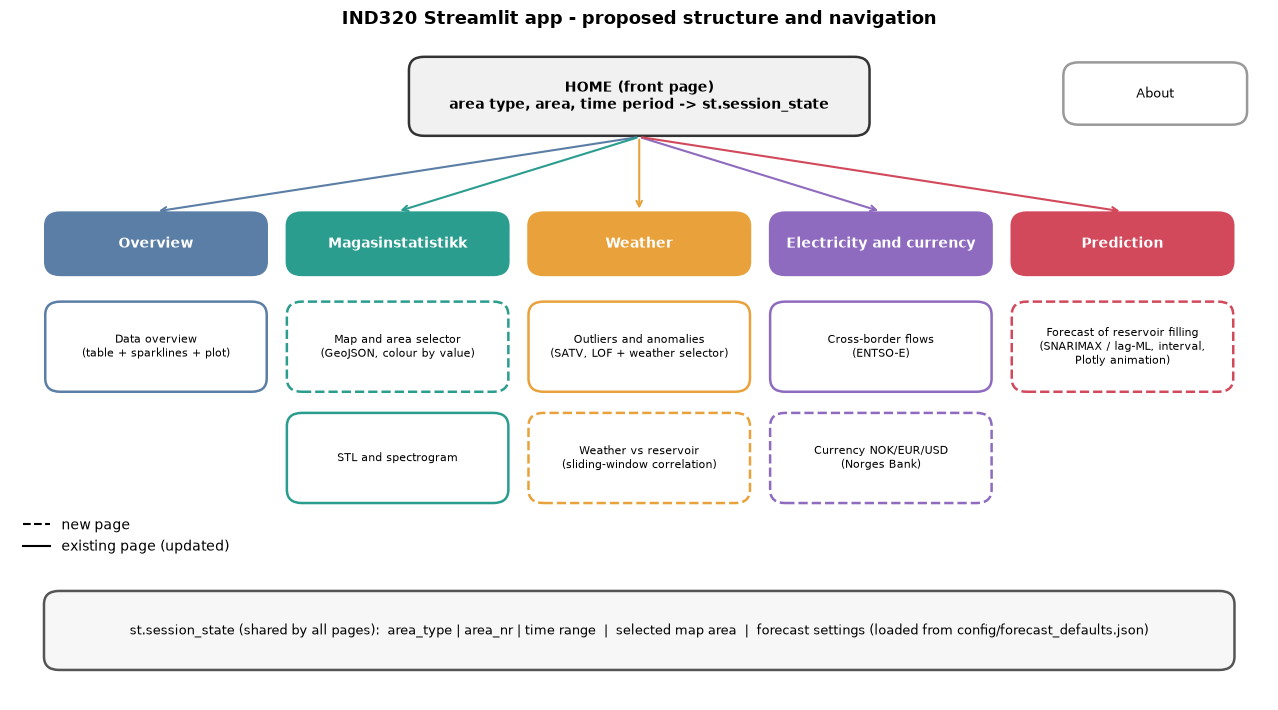

Saved docs/streamlit_structure.png (put your own hand-drawn version here if you prefer).


In [34]:
from matplotlib.patches import FancyBboxPatch

GROUPS = {   # group -> (colour, [(page title, 'new' | 'update')])
    "Overview":             ("#5b7ea6", [("Data overview\n(table + sparklines + plot)", "update")]),
    "Magasinstatistikk":    ("#2a9d8f", [("Map and area selector\n(GeoJSON, colour by value)", "new"),
                                         ("STL and spectrogram", "update")]),
    "Weather":              ("#e9a23b", [("Outliers and anomalies\n(SATV, LOF + weather selector)", "update"),
                                         ("Weather vs reservoir\n(sliding-window correlation)", "new")]),
    "Electricity and currency": ("#8e6bbf", [("Cross-border flows\n(ENTSO-E)", "update"),
                                             ("Currency NOK/EUR/USD\n(Norges Bank)", "new")]),
    "Prediction":           ("#d1495b", [("Forecast of reservoir filling\n(SNARIMAX / lag-ML, interval,\nPlotly animation)", "new")]),
}

fig, ax = plt.subplots(figsize=(13, 7.2))
ax.set_xlim(0, 100)
ax.set_ylim(0, 60)
ax.axis("off")


def box(x, y, w, h, text, color, dashed=False, fc=None, fs=9, bold=False, tc="black"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1.2", linewidth=1.8,
                                edgecolor=color, facecolor=fc or "white", linestyle="--" if dashed else "-"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else None, color=tc)


box(32, 51, 36, 6.5, "HOME (front page)\narea type, area, time period -> st.session_state", "#333333", fc="#f1f1f1", fs=10, bold=True)
n = len(GROUPS)
col_w, gap = 17, 2.2
x0 = (100 - (n * col_w + (n - 1) * gap)) / 2
for i, (gname, (color, pages)) in enumerate(GROUPS.items()):
    x = x0 + i * (col_w + gap)
    box(x, 38.5, col_w, 5, gname, color, fc=color, fs=10, bold=True, tc="white")
    ax.annotate("", xy=(x + col_w / 2, 43.9), xytext=(50, 50.6),
                arrowprops=dict(arrowstyle="->", color=color, lw=1.5, connectionstyle="arc3,rad=0"))
    for j, (title, kind) in enumerate(pages):
        box(x, 28 - j * 10, col_w, 7.5, title, color, dashed=(kind == "new"), fs=8)

box(3, 3, 94, 6.5, "st.session_state (shared by all pages):  area_type | area_nr | time range  |  selected map area  |  "
    "forecast settings (loaded from config/forecast_defaults.json)", "#555555", fc="#f7f7f7", fs=9)
box(84, 52, 14, 5, "About", "#999999", fs=9)
ax.plot([0], [0], color="k", ls="--", label="new page")
ax.plot([0], [0], color="k", ls="-", label="existing page (updated)")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.2), frameon=False)
ax.set_title("IND320 Streamlit app - proposed structure and navigation", fontsize=13, fontweight="bold")
plt.tight_layout()
(ROOT / "docs").mkdir(exist_ok=True)
fig.savefig(ROOT / "docs" / "streamlit_structure.png", dpi=150)
plt.show()
print("Saved docs/streamlit_structure.png (put your own hand-drawn version here if you prefer).")

**Log** 

I began with the Norges Bank API. The answer has many descriptive columns, so the parser picks BASE_CUR, TIME_PERIOD and OBS_VALUE by name, and because rates only exist for banking days (the longest gap in my data was 6 days) I forward-fill them to calendar days before averaging per week. For the timezone question I compared the four sources with real responses. NVE and Norges Bank only give dates (NVE on weekday SUN), while ENTSO-E is in UTC and Open-Meteo uses whatever timezone I ask for. The ENTSO-E check gave 25 hours on 27 October. The real risk is not the offset but the definition of the day, week and year, so I download hourly data in UTC, convert to Europe/Oslo only when grouping, and use daily weather with Europe/Oslo on the NVE week grid.

For forecasting I wrote one function, forecast_fill(), with River's SNARIMAX and a lag-based model. Both use weekly data, because the target is weekly and a seasonal period of 52 trains in a fraction of a second. I tested 34 settings with a walk-forward backtest (6 origins, 26 weeks) against a seasonal-naive benchmark. 33 settings beat it, and the best was lag_ml + currency (EURNOK) with MAE 0.081, which is now the default in the app. I was expecting a lot of error this time as well. but from previuos experience, i did the instalation and all before runting the code. 

**Bonus task**. I chose Confidence intervals in SARIMAX: interval=True trains two extra models with optim.losses.Quantile.

**Use of AI**

I used Claude (Anthropic) as a coding assistant and tutor for part 4. It helped me

* plan the notebook according to the assignment text and write the first version of the code for the Norges Bank download, the timezone checks, the River forecast function and the testing code;
* suggest what to test (walk-forward backtest, seasonal-naive benchmark, anomalies instead of raw series for correlations);
* explain River's `SNARIMAX` and the quantile loss for intervals.

I ran all code on my own computer with the real APIs, read the printed results, and wrote the log myself. Parts of the text in the findings sections are generated from the result tables by code in this notebook, and are therefore not written by hand. 